# CDC BRFSS Data Cleaning, Feature Engineering & Analytics Pipeline
> **Dataset:** CDC Behavioral Risk Factor Surveillance System (BRFSS) — `BRFSS_2024_Expanded_Analysis.csv` (124 curated analytical columns, 457,670 survey records from 2024).  
> **Architecture:** Out-of-Core Chunked Streaming Pipeline with Zero Restoration, SAS Underflow Normalization, Fixed-Point Decimal Rescaling, Leakage-Free Predictive Modeling, and Survey-Weighted Statistical Analytics.  
> **Portability:** Fully self-contained. Runs on any operating system (Windows / macOS / Linux) using dynamic relative path resolution.

---

### Pipeline Architecture Overview
```
BRFSS_2024_Expanded_Analysis.csv (124 cols, 457,670 rows)
  │
  ├── [Step 0]      Initial Data Exploration (Types, Duplicates, Missing, Unique Values)
  ├── [Step 1-3]    Stream Discovery & Diagnostic Sample Profiling (100k rows)
  ├── [Step 4-7]    Hygiene Logic, Zero-Restoration Rules & Prototype Testing
  ├── [Step 8]      Production Chunked Cleaning Pipeline ───► BRFSS_clean.csv
  ├── [Step 9-11]   Raw-vs-Clean Profiling, Validation & Outlier Capping
  ├── [Step 12-14]  Feature Engineering, SDOH Exploration & Survey-Weighted ML Classifier (Leakage-Free)
  ├── [Step 15]     Visual Analytics (Demographics, Modules, Physical & Mental Health)
  └── [Step 16-17]  Survey-Weighted Prevalence & Multivariable Interactive Heatmap
```


---
## 1. Environment Setup & Global Configuration <a id='sec-1'></a>

Initialize core libraries, configure structured logging, suppress harmless deprecation warnings, and centralize dataset paths.


In [1]:
# Section 1: Setup, Logging & Configuration
import logging
import warnings
import time
import re

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Structured Logging Configuration 
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s",
    datefmt="%Y-%m-%d %H:%M:%S",
    handlers=[
        logging.StreamHandler(),
        logging.FileHandler('pipeline_execution.log', mode='a', encoding='utf-8')
    ]
)
logger = logging.getLogger("BRFSS_Pipeline")
logger.info("Logging initialized. Starting BRFSS Pipeline execution.")

# Notebook Environment Settings 
warnings.filterwarnings("ignore")
pd.set_option('future.no_silent_downcasting', True)
sns.set_theme(style="whitegrid")

# File Paths & Processing Parameters
RAW_FILE = 'BRFSS_2024_Expanded_Analysis.csv'
CLEAN_FILE = 'BRFSS_clean.csv'
PLANNING_FILE = 'star_schema_planning.csv'
COMPARE_NULLS = 'compare_nulls.csv'

CHUNKSIZE = 100_000
SAMPLE_SIZE = 50_000

logger.info("Environment configuration ready.")
logger.info(f"Source raw dataset path: {RAW_FILE}")
logger.info(f"Target clean dataset path: {CLEAN_FILE}")

2026-10-31 12:24:24 [INFO] Logging initialized. Starting BRFSS Pipeline execution.
2026-10-31 12:24:24 [INFO] Environment configuration ready.
2026-10-31 12:24:24 [INFO] Source raw dataset path: BRFSS_2024_Expanded_Analysis.csv
2026-10-31 12:24:24 [INFO] Target clean dataset path: BRFSS_clean.csv


### Step 0: Initial Data Exploration (Raw File) <a id='step-0'></a>
First look at the raw dataset before any cleaning:
- Shape, memory footprint and **data types** (including text columns that look numeric).
- **Duplicates:** duplicate rows and column names on a 100k-row sample, plus a full-file streamed check for duplicate rows and duplicate `SEQNO` values.
- **Missing values:** overall counts, heavily missing columns and fully empty columns.
- **Unique values:** per-column profile (dtype, null %, unique count, most frequent value, sample values) and cardinality groups.
- Numeric summary with percentiles.



In [2]:
# Step 0: first look at the raw data
logger.info("STEP 0: Starting initial data exploration of the raw file...")

raw = pd.read_csv(RAW_FILE, nrows=100000, low_memory=False)

raw.info(verbose=True, show_counts=True, memory_usage="deep")
print("\nduplicate rows in the sample:", raw.duplicated().sum())
print("\nunique values per column:\n", raw.nunique())

# 1% and 99% help spot odd values like 77/99 codes
print("\nnumeric summary:")
print(raw.describe(percentiles=[.01, .25, .5, .75, .99]).T.round(2))

# duplicates on the full file, read in chunks
logger.info("STEP 0: Streaming full raw file for duplicate detection...")

seq_col = [c for c in raw.columns if "SEQNO" in c]
seq_col = seq_col[0] if seq_col else None

hashes_all, hashes_no_id, seqno = [], [], []
for chunk in pd.read_csv(RAW_FILE, dtype=str, keep_default_na=False, chunksize=CHUNKSIZE):
    hashes_all.append(pd.util.hash_pandas_object(chunk, index=False))
    if seq_col:
        hashes_no_id.append(pd.util.hash_pandas_object(chunk.drop(columns=[seq_col]), index=False))
        seqno.append(chunk[seq_col])

hashes_all = pd.concat(hashes_all)
print("\ntotal rows:", len(hashes_all))
print("duplicate rows:", hashes_all.duplicated().sum())

if seq_col:
    print("duplicate SEQNO:", pd.concat(seqno).duplicated().sum())
    print("duplicate rows ignoring SEQNO:", pd.concat(hashes_no_id).duplicated().sum())

logger.info("STEP 0: Initial exploration complete.")

2026-10-31 12:24:31 [INFO] STEP 0: Starting initial data exploration of the raw file...


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 124 columns):
 #    Column                                                                                                                                  Non-Null Count   Dtype  
---   ------                                                                                                                                  --------------   -----  
 0    State FIPS Code (_STATE)                                                                                                                100000 non-null  object 
 1    Annual Sequence Number (SEQNO)                                                                                                          100000 non-null  int64  
 2    Primary Sampling Unit (_PSU)                                                                                                            100000 non-null  int64  
 3    Sex of Respondent (SEXVAR)                      

2026-10-31 12:24:37 [INFO] STEP 0: Streaming full raw file for duplicate detection...



unique values per column:
 State FIPS Code (_STATE)                                                                                                                     14
Annual Sequence Number (SEQNO)                                                                                                            13086
Primary Sampling Unit (_PSU)                                                                                                              13086
Sex of Respondent (SEXVAR)                                                                                                                    2
General Health (GENHLTH)                                                                                                                      7
                                                                                                                                          ...  
Hispanic, Latino/a, or Spanish origin calculated variable (_HISPANC)                                        

2026-10-31 12:24:54 [INFO] STEP 0: Initial exploration complete.



total rows: 457670
duplicate rows: 0
duplicate SEQNO: 413757
duplicate rows ignoring SEQNO: 0


---
## 2. Phase 1: Initial Discovery & Schema Planning <a id='sec-2'></a>

Inspect headers, export columns to design star-schema tables, and run automated diagnostics on survey structure.

### Step 1: Column Discovery via Chunk Streaming <a id='step-1'></a>
Read only the header row using nrows=0 to safely discover all 124 columns without loading the full 1.2 GB dataset into RAM.


In [3]:
# Step 1: get the column names
logger.info("STEP 1: Beginning column discovery...")

# nrows=0 reads only the header row
all_columns = pd.read_csv(RAW_FILE, nrows=0).columns.tolist()
logger.info(f"STEP 1: Successfully extracted {len(all_columns)} column headers.")

print(f"Total columns found: {len(all_columns)}")
print(f"Sample of first 10 columns: {all_columns[:10]}")

2026-10-31 13:19:47 [INFO] STEP 1: Beginning column discovery...
2026-10-31 13:19:47 [INFO] STEP 1: Successfully extracted 124 column headers.


Total columns found: 124
Sample of first 10 columns: ['State FIPS Code (_STATE)', 'Annual Sequence Number (SEQNO)', 'Primary Sampling Unit (_PSU)', 'Sex of Respondent (SEXVAR)', 'General Health (GENHLTH)', 'Number of Days Physical Health Not Good (PHYSHLTH)', 'Number of Days Mental Health Not Good (MENTHLTH)', 'Poor Physical or Mental Health (POORHLTH)', 'What is Your Current Primary Source of Health Care Coverage? (PRIMINS2)', 'Have Personal Health Care Provider? (PERSDOC3)']


### Step 2: Star-Schema Planning Export & Column Inspection <a id='step-2'></a>
Export column names into a planning spreadsheet for fact/dimension table modeling, and print them in readable batches.


In [4]:
# Step 2: Export column list for Star-Schema planning
logger.info("STEP 2: Exporting column names to planning file...")

col_df = pd.DataFrame({'Column_Name': all_columns})
col_df['Suggested_Table'] = ''  # Blank column to fill in later during data modeling

col_df.to_csv(PLANNING_FILE, index=False)
logger.info(f"STEP 2: Saved planning catalog to '{PLANNING_FILE}'")

print(f"Saved {len(all_columns)} columns to: {PLANNING_FILE}")
print("\nSample batches of columns:")
for i in range(0, min(len(all_columns), 40), 10):
    print(f"Batch {i//10 + 1}:", all_columns[i:i+10])

2026-10-31 13:19:49 [INFO] STEP 2: Exporting column names to planning file...
2026-10-31 13:19:49 [INFO] STEP 2: Saved planning catalog to 'star_schema_planning.csv'


Saved 124 columns to: star_schema_planning.csv

Sample batches of columns:
Batch 1: ['State FIPS Code (_STATE)', 'Annual Sequence Number (SEQNO)', 'Primary Sampling Unit (_PSU)', 'Sex of Respondent (SEXVAR)', 'General Health (GENHLTH)', 'Number of Days Physical Health Not Good (PHYSHLTH)', 'Number of Days Mental Health Not Good (MENTHLTH)', 'Poor Physical or Mental Health (POORHLTH)', 'What is Your Current Primary Source of Health Care Coverage? (PRIMINS2)', 'Have Personal Health Care Provider? (PERSDOC3)']
Batch 2: ['Could Not Afford To See Doctor (MEDCOST1)', 'Length of time since last routine checkup (CHECKUP1)', 'Exercise in Past 30 Days (EXERANY2)', 'Last Visited Dentist or Dental Clinic (LASTDEN4)', 'Number of Permanent Teeth Removed (RMVTETH4)', 'Ever Diagnosed with Heart Attack (CVDINFR4)', 'Ever Diagnosed with Angina or Coronary Heart Disease (CVDCRHD4)', 'Ever Diagnosed with a Stroke (CVDSTRK3)', 'Ever Told Had Asthma (ASTHMA3)', 'Still Have Asthma (ASTHNOW)']
Batch 3: ['(Eve

### Step 3: Diagnostic Profiling (Sample Analysis) <a id='step-3'></a>
Run deep diagnostics on the first 100,000 rows to detect:
1. High-cardinality categorical columns hiding raw numbers.
2. Questionnaire skip-logic triggers (e.g., *'Go to LL.02'*, *'Terminate Phone Call'*).
3. Highly correlated missingness blocks (social determinants of health and mental health blocks).
4. Survey weight (`_LLCPWT`) distribution skew.


In [5]:
# Step 3: diagnostic profiling on a 100k sample
logger.info("STEP 3: Loading 100k row sample for structural diagnostics...")
df_diag = pd.read_csv(RAW_FILE, nrows=100_000, low_memory=False)
logger.info(f"STEP 3: Diagnostic sample loaded. Shape: {df_diag.shape}")

# 1. text columns with many unique values (numbers hiding in text?)
print("--- Categoricals with unusually high cardinality ---")
unique_counts = df_diag.select_dtypes(include='object').nunique()
print(unique_counts[(unique_counts > 10) & (unique_counts < 1000)].head(15))

# 2. skip logic text (e.g. "- Go to Section...")
print("\n--- Skip Logic Triggers Found ---")
skip_phrases = df_diag.select_dtypes(include='object').apply(
    lambda col: col.str.extract(r'(- Go to .*|Terminate.*)', expand=False).dropna().unique()
)
print(skip_phrases[skip_phrases.apply(len) > 0].head(10))

# 3. missing values that go together (blocks of questions skipped together)
print("\n--- Top Missingness Correlations (First 50 cols) ---")
sample_cols = df_diag.columns[:50]
missing_corr = df_diag[sample_cols].isna().corr().unstack().sort_values(ascending=False)
print(missing_corr[missing_corr < 1.0].drop_duplicates().head(5))

# 4. survey weight distribution (the raw column name is long, so search by substring)
print("\n--- Survey Weight Distribution ---")
weight_col = [c for c in df_diag.columns if '_LLCPWT' in c]
if weight_col:
    weights = pd.to_numeric(df_diag[weight_col[0]], errors='coerce')
    print(weights.describe(percentiles=[.01, .5, .90, .99]).round(2))
else:
    print("Survey weight column not found.")

logger.info("STEP 3: Diagnostic profiling complete.")

2026-10-31 13:19:53 [INFO] STEP 3: Loading 100k row sample for structural diagnostics...
2026-10-31 13:19:56 [INFO] STEP 3: Diagnostic sample loaded. Shape: (100000, 124)


--- Categoricals with unusually high cardinality ---
State FIPS Code (_STATE)                                                      14
Number of Days Physical Health Not Good (PHYSHLTH)                            32
Number of Days Mental Health Not Good (MENTHLTH)                              32
Poor Physical or Mental Health (POORHLTH)                                     32
What is Your Current Primary Source of Health Care Coverage? (PRIMINS2)       13
Income Level (INCOME3)                                                        13
How old when you first started smoking? (LCSFIRST)                            76
On average, how many cigarettes do you smoke each day? (LCSNUMCG)             86
Computed drink-occasions-per-day (DROCDY4_)                                   36
Computed number of drinks of alcohol beverages per week (_DRNKWK3)           199
Age When First Told You Had Diabetes (DIABAGE4)                               96
How old when you last smoked? (LCSLAST_)                

2026-10-31 13:20:00 [INFO] STEP 3: Diagnostic profiling complete.


How often get emotional support needed (EMTSUPRT)                                 How often do you feel lonely? (SDLONELY)                                                                                 0.998959
Were you not able to pay your bills? (SDHBILLS)                                   Were you not able to pay utility bills or threatened to lose service? (SDHUTILS)                                         0.998939
Were you not able to pay utility bills or threatened to lose service? (SDHUTILS)  Has a lack of reliable transportation kept you from appointments, meetings, work, or getting things needed (SDHTRNSP)    0.998819
Neighborhood Safe From Crime (HOWSAFE1)                                           Has a lack of reliable transportation kept you from appointments, meetings, work, or getting things needed (SDHTRNSP)    0.998759
How often get emotional support needed (EMTSUPRT)                                 Satisfaction with life (LSATISFY)                                     

---
## 3. Phase 2: Modular Cleaning Architecture & Testing <a id='sec-3'></a>

Encapsulate domain-specific cleaning logic into pure, reusable functions and validate on a 50k test sample.

### Step 4: Define Advanced Cleaning Function <a id='step-4'></a>
Cleans BRFSS survey idiosyncrasies:
- Drops 19 highly correlated administrative phone screening columns with ~100% missingness.
- Strips skip-logic routing phrases (*'Go to...'*, *'Terminate'*).
- Maps *'Don't know'*, *'Refused'*, and *'Not sure'* responses to `np.nan`.
- Recodes 30-day health indicators (`PHYSHLTH`, `MENTHLTH`, `POORHLTH`): maps BRFSS code 88 to 0 days, 77/99 to NaN, and clamps to [0, 30].
- Recodes `DIABAGE4` (age diagnosed with diabetes: codes 98/99 mapped to NaN).


In [6]:
# Step 4: define the cleaning function
logger.info("STEP 4: Defining apply_advanced_cleaning()...")

def code_name(c):
    # "Some long question (CODE)" -> "CODE"
    m = re.search(r"\(([^()]*)\)\s*$", c)
    return m.group(1).strip() if m else c.strip()

def codes(cols):
    out, seen = [], {}
    for c in cols:
        k = code_name(c)
        seen[k] = seen.get(k, 0) + 1
        out.append(k if seen[k] == 1 else f"{k}_{seen[k]}")
    return out

def apply_advanced_cleaning(df):
    df = df.copy()
    df.columns = codes(df.columns)   # rename first so the checks below can find the columns

    # 1. drop phone screening / admin columns if they exist
    phone_cols = [
        'CTELENM1', 'PVTRESD1', 'COLGHOUS', 'STATERE1', 'CELPHON1', 'LADULT1',
        'NUMADULT', 'SAFETIME', 'CTELNUM1', 'CELLFON5', 'CADULT1', 'CSTATE1',
        'LANDLINE', 'HHADULT', 'PVTRESD3', 'CCLGHOUS', 'RESPSLC1', 'RCSGEND1', 'RCSXBRTH'
    ]
    to_drop = [c for c in phone_cols if c in df.columns]
    df = df.drop(columns=to_drop)
    logger.debug(f"Dropped {len(to_drop)} administrative columns.")

    # 2. remove routing text ("- Go to ...") and turn "don't know" / "refused" into NaN
    skip_re = re.compile(r"\s*-\s*(?:Go to|If LL|Terminate).*$", re.IGNORECASE)
    miss_re = re.compile(r"^(?:don['’]?t know|refused|i don['’]?t know|doctor refused|not eligible, don['’]?t know)", re.IGNORECASE)

    for c in df.columns:
        s = df[c].astype(str).str.strip().str.replace(skip_re, "", regex=True)
        df[c] = s.mask(s.str.contains(miss_re, na=False) | (s == 'nan'))

    # 3. 30-day health columns: "None" / 88 means 0 days, 77/99 and anything over 30 become NaN
    for col, flag in [('PHYSHLTH', '_PHYS14D'), ('MENTHLTH', '_MENT14D'), ('POORHLTH', None)]:
        if col not in df.columns:
            continue
        nums = pd.to_numeric(df[col], errors='coerce')
        text = df[col].astype(str)
        is_zero = (text.str.lower() == 'none') | (text == '88')
        if flag in df.columns:
            is_zero |= df[flag].astype(str).str.startswith('Zero', na=False)
        if col == 'POORHLTH':
            # people with 0 physical and 0 mental bad days skip this question
            is_zero |= (df.get('PHYSHLTH', 1) == 0) & (df.get('MENTHLTH', 1) == 0)
        df[col] = np.where(is_zero, 0.0, np.where((nums >= 0) & (nums <= 30), nums, np.nan))

    # 4. children: "No children" means 0
    if 'CHILDREN' in df.columns and '_CHLDCNT' in df.columns:
        nums = pd.to_numeric(df['CHILDREN'], errors='coerce')
        is_zero = df['_CHLDCNT'].astype(str).str.contains('No children', case=False, na=False) | df['CHILDREN'].astype(str).str.contains(r'[Ee]-79', na=False)
        df['CHILDREN'] = np.where(is_zero, 0.0, np.where(nums >= 0, nums, np.nan))

    # 5. DIABAGE4: 98 and 99 mean unknown / refused
    if 'DIABAGE4' in df.columns:
        age = pd.to_numeric(df['DIABAGE4'], errors='coerce')
        df['DIABAGE4'] = age.mask(age >= 98)

    return df

logger.info("STEP 4: apply_advanced_cleaning() registered successfully.")

2026-10-31 13:20:07 [INFO] STEP 4: Defining apply_advanced_cleaning()...
2026-10-31 13:20:07 [INFO] STEP 4: apply_advanced_cleaning() registered successfully.


### Step 5: Load a 50k Sample and Run the Cleaning Function <a id='step-5'></a>
Load 50,000 raw rows and run `apply_advanced_cleaning()` on them, so the cleaning rules can be tested before processing the whole file.

In [7]:
# Step 5: load a 50k sample and run the cleaning function on it
logger.info(f"STEP 5: Loading {SAMPLE_SIZE:,} rows for prototype cleaning test...")

df_sample = pd.read_csv(RAW_FILE, dtype=str, nrows=SAMPLE_SIZE, keep_default_na=False, na_values=[""])
logger.info(f"STEP 5: Loaded raw sample: {df_sample.shape}. Applying cleaning rules...")

df_clean_sample = apply_advanced_cleaning(df_sample)
logger.info(f"STEP 5: Cleaning completed. Cleaned sample shape: {df_clean_sample.shape}")

2026-10-31 13:20:15 [INFO] STEP 5: Loading 50,000 rows for prototype cleaning test...
2026-10-31 13:20:16 [INFO] STEP 5: Loaded raw sample: (50000, 124). Applying cleaning rules...
2026-10-31 13:20:23 [INFO] STEP 5: Cleaning completed. Cleaned sample shape: (50000, 124)


### Step 6: Diagnostics on the Cleaned Sample <a id='step-6'></a>
Check the cleaned sample: missing values, target class balance, numeric distributions (health-day columns should now have real zeros) and columns with unexpected cardinality.

In [8]:
# Step 6: check the cleaned sample
logger.info("STEP 6: Running diagnostics on the cleaned sample...")

# missing values after cleaning
print("Cleaned sample shape:", df_clean_sample.shape)
print("\n--- Top 20 columns by % missing ---")
print((df_clean_sample.isna().mean() * 100).sort_values(ascending=False).head(20).round(2))

# target columns
print("\n--- Target columns (% of rows) ---")
for t in ['DIABETE4', 'CVDINFR4', 'CVDSTRK3', 'CHCKDNY2', 'ADDEPEV3']:
    if t in df_clean_sample.columns:
        print(f"\n{t}")
        print((df_clean_sample[t].value_counts(dropna=False, normalize=True) * 100).round(1))

# numeric columns
print("\n--- Numeric columns ---")
num_cols = [c for c in ['_BMI5', 'PHYSHLTH', 'MENTHLTH', '_DRNKWK3', '_PACKDAY', 'DIABAGE4'] if c in df_clean_sample.columns]
if num_cols:
    print(df_clean_sample[num_cols].apply(pd.to_numeric, errors='coerce').describe(percentiles=[.01, .5, .99]).round(2).T)

# columns with 10-100 unique values (numbers hiding in text?)
print("\n--- Unexpected cardinality ---")
nunique = df_clean_sample.nunique()
print(nunique[(nunique > 10) & (nunique < 100)].sort_values(ascending=False).head(15))

logger.info("STEP 6: Sample diagnostics completed.")

2026-10-31 13:20:30 [INFO] STEP 6: Running diagnostics on the cleaned sample...


Cleaned sample shape: (50000, 124)

--- Top 20 columns by % missing ---
ACEDEPRS    100.00
DIABTYPE    100.00
DIABEDU1    100.00
MARJSMOK     96.71
_LCSPSTF     94.23
CAREGIV1     89.90
FIREARM5     88.80
DIABAGE4     87.13
CIMEMLO1     86.97
ASTHNOW      84.36
PREGNANT     81.80
PREDIAB2     79.82
_LCSYQTS     73.40
LCSLAST_     73.40
_PACKYRS     68.10
_PNEUMO3     67.86
_LCSYSMK     67.06
LCSNUMC_     66.99
LCSNUMCG     66.99
_PACKDAY     66.99
dtype: float64

--- Target columns (% of rows) ---

DIABETE4
DIABETE4
No                                            82.8
Yes                                           13.7
No, pre-diabetes or borderline diabetes        2.5
Yes, but female told only during pregnancy     0.7
NaN                                            0.2
Name: proportion, dtype: float64

CVDINFR4
CVDINFR4
No     93.7
Yes     5.6
NaN     0.7
Name: proportion, dtype: float64

CVDSTRK3
CVDSTRK3
No     95.2
Yes     4.4
NaN     0.4
Name: proportion, dtype: float64

CHCKDNY2
CHCK

2026-10-31 13:20:30 [INFO] STEP 6: Sample diagnostics completed.


_LCSYQTS    93
DIABAGE4    91
HTM4        85
_LCSYSMK    81
LCSLAST_    75
LCSFIRST    70
LCSNUMCG    67
_PACKDAY    67
LCSNUMC_    67
_AGE80      63
ALCDAY4     37
DROCDY4_    34
AVEDRNK4    33
PHYSHLTH    31
MENTHLTH    31
dtype: int64


### Step 7: Short Column-Code Extraction Utility <a id='step-7'></a>
Raw BRFSS headers have verbose descriptions such as `Reported Age in Years (_AGE80)`. This utility parses the bracketed code `_AGE80` as the clean column name.


In [9]:
# ── Step 7: Define column header regex shortener ──────────────────────────────
logger.info("STEP 7: Defining extract_column_codes() & codes()...")

def extract_column_codes(df):
    """Rename DataFrame columns from 'Verbose Description (CODE)' to 'CODE'."""
    new_cols = {}
    for col in df.columns:
        match = re.search(r'\(([^()]*)\)\s*$', col)
        new_cols[col] = match.group(1).strip() if match else col.strip()
    return df.rename(columns=new_cols)

def code_name(c):
    """Extract bracketed code from a single string."""
    m = re.search(r"\(([^()]*)\)\s*$", c)
    return m.group(1).strip() if m else c.strip()

def codes(cols):
    """Extract deduplicated code names for a list of column headers."""
    out, seen = [], {}
    for c in cols:
        k = code_name(c)
        seen[k] = seen.get(k, 0) + 1
        out.append(k if seen[k] == 1 else f"{k}_{seen[k]}")
    return out

logger.info("STEP 7: Extraction utilities defined.")

2026-10-31 13:24:36 [INFO] STEP 7: Defining extract_column_codes() & codes()...
2026-10-31 13:24:36 [INFO] STEP 7: Extraction utilities defined.


---
## 4. Phase 3: Production Cleaning Pipeline & Validation <a id='sec-4'></a>

Stream the full raw file in chunks, write the single clean output file, then validate it against the raw data.

### Step 8: Execute Full-Dataset Chunked Cleaning Pipeline <a id='step-8'></a>
The final pipeline streams the raw file in chunks and writes the single clean output file `BRFSS_clean.csv`:
- Shortens column headers to their bracketed codes (e.g. `_AGE80`).
- Strips skip-logic routing phrases and maps *'Don't know'* / *'Refused'* responses to `NaN`.
- Restores swallowed zeros in `PHYSHLTH`, `MENTHLTH`, `POORHLTH` and `CHILDREN`.
- Normalizes tiny SAS underflow values (e.g. `5.4e-79` in `_DRNKWK3`) to `0`.
- Converts numeric columns to float and rescales fixed-point fields (`_BMI5`, `WTKG3`, `HTM4`, etc.) by dividing by 100.
- Parses `IDATE` to datetime and creates the `is_complete` interview flag.
- Drops only the administrative columns that exist in the file. `SEQNO` is kept as the unique record ID.

In [10]:
# ── Step 8: Execute Full-Dataset Cleaning ──────────────────────────────────
logger.info("STEP 8: Executing final chunked cleaning pipeline...")

new_cols = codes(pd.read_csv(RAW_FILE, nrows=0).columns)

drop_cols = [
    'CTELENM1', 'PVTRESD1', 'COLGHOUS', 'STATERE1', 'CELPHON1', 'LADULT1', 'NUMADULT', 'RESPSLC1',
    'SAFETIME', 'CTELNUM1', 'CELLFON5', 'CADULT1', 'PVTRESD3', 'CCLGHOUS', 'CSTATE1', 'LANDLINE', 'HHADULT',
    'RCSGEND1', 'RCSXBRTH'
]

skip_re = re.compile(r"\s*-\s*(?:Go to|If LL|Terminate).*$", re.IGNORECASE)
miss_re = re.compile(r"^(?:don['’]?t know|refused|i don['’]?t know|doctor refused|not eligible, don['’]?t know)", re.IGNORECASE)

plain = [
    "IDAY", "IYEAR", "_AGE80", "HTIN4", "_STSTR", "_STRWT", "_RAWRAKE", "_WT2RAKE",
    "_CLLCPWT", "_DUALCOR", "_LLCPWT2", "_LLCPWT", "LCSNUMC_", "LCSLAST_", "_LCSYSMK",
    "_PACKYRS", "_LCSYQTS"
]
scaled = ["_BMI5", "WTKG3", "HTM4", "_PACKDAY", "_DRNKWK3", "DROCDY4_"]
underflow_cols = ["_PACKYRS", "_LCSYQTS", "_LCSYSMK", "CHILDREN", "_DRNKWK3", "DROCDY4_"]

def clean(ch):
    """Standardize headers, strip skip logic, restore zeros, and convert numeric columns."""
    ch.columns = new_cols
    ch = ch.drop(columns=[c for c in drop_cols if c in ch.columns], errors='ignore')
    
    # 1. Strip skip routing and map non-response patterns
    for c in ch.columns:
        s = ch[c].str.strip().str.replace(skip_re, "", regex=True)
        ch[c] = s.mask(s.str.contains(miss_re, na=False) | (s == "Not Eligible, Don't know/Not sure, Refused, or Missing") | (s == 'nan'))
    
    # 2. Restore swallowed zeros in 30-day health indicators
    if 'PHYSHLTH' in ch.columns:
        phys_num = pd.to_numeric(ch['PHYSHLTH'], errors='coerce')
        is_zero_phys = ch['_PHYS14D'].astype(str).str.startswith('Zero', na=False) if '_PHYS14D' in ch.columns else False
        is_zero_phys |= (ch['PHYSHLTH'].astype(str).str.lower() == 'none') | (ch['PHYSHLTH'].astype(str) == '88')
        ch['PHYSHLTH'] = np.where(is_zero_phys, 0.0, np.where((phys_num >= 0) & (phys_num <= 30), phys_num, np.nan))

    if 'MENTHLTH' in ch.columns:
        ment_num = pd.to_numeric(ch['MENTHLTH'], errors='coerce')
        is_zero_ment = ch['_MENT14D'].astype(str).str.startswith('Zero', na=False) if '_MENT14D' in ch.columns else False
        is_zero_ment |= (ch['MENTHLTH'].astype(str).str.lower() == 'none') | (ch['MENTHLTH'].astype(str) == '88')
        ch['MENTHLTH'] = np.where(is_zero_ment, 0.0, np.where((ment_num >= 0) & (ment_num <= 30), ment_num, np.nan))

    if 'POORHLTH' in ch.columns:
        poor_num = pd.to_numeric(ch['POORHLTH'], errors='coerce')
        is_zero_poor = ((ch.get('PHYSHLTH', 1) == 0.0) & (ch.get('MENTHLTH', 1) == 0.0))
        is_zero_poor |= (ch['POORHLTH'].astype(str).str.lower() == 'none') | (ch['POORHLTH'].astype(str) == '88')
        ch['POORHLTH'] = np.where(is_zero_poor, 0.0, np.where((poor_num >= 0) & (poor_num <= 30), poor_num, np.nan))

    # 3. Restore Children 0s
    if 'CHILDREN' in ch.columns and '_CHLDCNT' in ch.columns:
        chld_num = pd.to_numeric(ch['CHILDREN'], errors='coerce')
        is_zero_chld = ch['_CHLDCNT'].astype(str).str.contains('No children', case=False, na=False) | ch['CHILDREN'].astype(str).str.contains(r'[Ee]-79', regex=True, na=False)
        ch['CHILDREN'] = np.where(is_zero_chld, 0.0, np.where(chld_num >= 0, chld_num, np.nan))

    # 4. Normalize SAS Underflow tokens (5.40E-79 -> 0)
    for col in underflow_cols:
        if col in ch.columns:
            s_uf = ch[col].astype(str)
            ch[col] = ch[col].mask(s_uf.str.contains(r'[Ee]-79', regex=True, na=False), '0')

    # 5. Convert designated plain & scaled numerics
    for c in plain + scaled:
        if c in ch.columns:
            ch[c] = pd.to_numeric(ch[c], errors="coerce")
            
    for c in ["_DRNKWK3", "DROCDY4_"]:
        if c in ch.columns:
            ch[c] = ch[c].mask(ch[c] <= 1e-6, 0)
            
    for c in scaled:
        if c in ch.columns:
            ch[c] = ch[c] / 100.0
            
    if "_LCSYQTS" in ch.columns:
        ch["_LCSYQTS"] = ch["_LCSYQTS"].mask(ch["_LCSYQTS"] < 0)
        
    if "IDATE" in ch.columns:
        ch["IDATE"] = pd.to_datetime(ch["IDATE"], errors="coerce")
        
    if "DISPCODE" in ch.columns:
        ch["is_complete"] = np.where(ch["DISPCODE"].astype(str).str.contains("Partial", case=False, na=False), 0, 1)
    else:
        ch["is_complete"] = 1
        
    return ch

t0_v2, first_v2, n_v2 = time.time(), True, 0
for ch in pd.read_csv(RAW_FILE, dtype=str, keep_default_na=False, na_values=[""], chunksize=CHUNKSIZE):
    ch = clean(ch)
    ch.to_csv(CLEAN_FILE, mode="w" if first_v2 else "a", header=first_v2, index=False)
    first_v2 = False
    n_v2 += len(ch)
    logger.info(f"  stream: {n_v2:,} rows written ({time.time()-t0_v2:.1f}s elapsed)...")

logger.info(f"STEP 8: Pipeline complete. Saved {n_v2:,} rows to '{CLEAN_FILE}'.")
print(f"Clean file written to: {CLEAN_FILE}")


2026-10-31 13:24:38 [INFO] STEP 8: Executing final chunked cleaning pipeline...
2026-10-31 13:24:57 [INFO]   stream: 100,000 rows written (19.1s elapsed)...
2026-10-31 13:25:16 [INFO]   stream: 200,000 rows written (37.8s elapsed)...
2026-10-31 13:25:35 [INFO]   stream: 300,000 rows written (57.0s elapsed)...
2026-10-31 13:25:54 [INFO]   stream: 400,000 rows written (76.1s elapsed)...
2026-10-31 13:26:05 [INFO]   stream: 457,670 rows written (86.5s elapsed)...
2026-10-31 13:26:05 [INFO] STEP 8: Pipeline complete. Saved 457,670 rows to 'BRFSS_clean.csv'.


Clean file written to: BRFSS_clean.csv


### Step 9: Full Differential Dataset Profiler (Raw vs Cleaned) <a id='step-9'></a>
Streams through both the raw and cleaned files to compute before-and-after statistics across all columns:
- Validates rows and dropped/added columns.
- Flags columns where null % decreased (potential implicit imputation) or increased (intentional mapping of refusal strings).
- Alerts on numeric columns whose mean changed by > 1%.
- Exports the detailed comparison audit to `compare_nulls.csv`.


In [11]:
# ── Step 9: Differential Dataset Profiler (Raw vs Cleaned) ───────────────────
logger.info("STEP 9: Profiling raw vs cleaned datasets...")

def profile(path, rename):
    stats, n = {}, 0
    for ch in pd.read_csv(path, dtype=str, keep_default_na=False, na_values=[""], chunksize=CHUNKSIZE):
        if rename: 
            ch.columns = codes(ch.columns)
        n += len(ch)
        for c in ch.columns:
            s = ch[c]
            x = pd.to_numeric(s, errors="coerce")
            st = stats.setdefault(c, {"nn": 0, "num": 0, "sum": 0.0, "min": np.inf, "max": -np.inf})
            st["nn"] += int(s.notna().sum())
            k = int(x.notna().sum())
            st["num"] += k
            if k:
                st["sum"] += float(x.sum())
                st["min"] = min(st["min"], float(x.min()))
                st["max"] = max(st["max"], float(x.max()))
    d = pd.DataFrame(stats).T.astype(float)
    d["nulls"] = n - d["nn"]
    d["null_pct"] = (d["nulls"] / n * 100).round(2)
    d["numeric"] = (d["num"] == d["nn"]) & (d["nn"] > 0)
    d["mean"] = (d["sum"] / d["num"].replace(0, np.nan)).round(3)
    d.attrs["rows"] = n
    return d

t_prof = time.time()
logger.info("Profiling raw file...")
po = profile(RAW_FILE, True)
logger.info("Profiling cleaned file...")
pn = profile(CLEAN_FILE, False)
logger.info(f"Profiling completed in {time.time()-t_prof:.1f}s.")

common   = [c for c in po.index if c in pn.index]
only_old = [c for c in po.index if c not in pn.index]
only_new = [c for c in pn.index if c not in po.index]

print("=== DATASET SIZE COMPARISON ===")
print(f"Original: {po.attrs['rows']:,} rows × {len(po)} columns")
print(f"Cleaned : {pn.attrs['rows']:,} rows × {len(pn)} columns")
print(f"\nColumns Dropped ({len(only_old)}): {only_old}")
print(f"\nColumns Added ({len(only_new)}): {only_new}")

cmp = pd.DataFrame({"null%_before": po.loc[common, "null_pct"], "null%_after": pn.loc[common, "null_pct"]})
cmp["change"] = (cmp["null%_after"] - cmp["null%_before"]).round(2)

print("\n=== TOP 20 COLUMNS WITH INCREASED NULLS (Refusal/Skip -> NaN) ===")
print(cmp[cmp["change"] > 0.05].sort_values("change", ascending=False).head(20).to_string())

cmp.to_csv(COMPARE_NULLS)
logger.info(f"STEP 9: Detailed null comparison exported to '{COMPARE_NULLS}'.")

2026-10-31 13:26:05 [INFO] STEP 9: Profiling raw vs cleaned datasets...
2026-10-31 13:26:05 [INFO] Profiling raw file...
2026-10-31 13:26:50 [INFO] Profiling cleaned file...
2026-10-31 13:27:35 [INFO] Profiling completed in 90.4s.
2026-10-31 13:27:35 [INFO] STEP 9: Detailed null comparison exported to 'compare_nulls.csv'.


=== DATASET SIZE COMPARISON ===
Original: 457,670 rows × 124 columns
Cleaned : 457,670 rows × 125 columns

Columns Dropped (0): []

Columns Added (1): ['is_complete']

=== TOP 20 COLUMNS WITH INCREASED NULLS (Refusal/Skip -> NaN) ===
          null%_before  null%_after  change
_LCSPSTF         11.24        93.49   82.25
_HCVU654          0.00        41.74   41.74
_INCOMG1          0.00        19.10   19.10
INCOME3           2.03        19.10   17.07
_RFBING6          0.00        10.36   10.36
_DRNKWK3          0.00        10.20   10.20
_RFDRHV9          0.00        10.20   10.20
DRNKANY6          0.00         9.57    9.57
DROCDY4_          0.00         9.57    9.57
_RFBMI5           0.00         9.40    9.40
_CURECI3          0.00         7.16    7.16
_SMOKER3          0.00         7.00    7.00
_RFSMOK3          0.00         7.00    7.00
PNEUVAC4          9.35        16.14    6.79
_PNEUMO3         60.81        66.83    6.02
WEIGHT2           2.69         7.95    5.26
_FLSHOT7         6

### Step 10: Validate the Cleaned Dataset & Column Distributions <a id='step-10'></a>
Check completeness rates across key survey columns and view descriptive summaries of continuous variables (`HTM4`, `_DRNKWK3`, `_BMI5`, `WTKG3`).


In [12]:
# ── Step 10: Validate Clean File ───────────────────────────────────────────
logger.info("STEP 10: Validating final clean dataset...")

cols_check = [
    'CHILDREN', 'MENTHLTH', 'PHYSHLTH', 'DRNK3GE5', 'POORHLTH', 'AVEDRNK4',
    'RMVTETH4', 'CPDEMO1C', 'CHKHEMO3', 'NUMPHON4', 'HTM4', '_DRNKWK3', '_BMI5', 'WTKG3'
]

avail_v2_cols = pd.read_csv(CLEAN_FILE, nrows=0).columns
cols_check = [c for c in cols_check if c in avail_v2_cols]

nulls_v2, n_rows_v2 = pd.Series(0.0, index=cols_check), 0
for ch in pd.read_csv(CLEAN_FILE, usecols=cols_check, keep_default_na=False, na_values=[""], chunksize=CHUNKSIZE):
    nulls_v2 += ch.isna().sum()
    n_rows_v2 += len(ch)

print(f"Total Rows Checked: {n_rows_v2:,}")
print("\nMissingness Percentage for Key Columns:")
print((nulls_v2 / n_rows_v2 * 100).round(1).to_string())

sample_cols = [c for c in ["HTM4", "_DRNKWK3", "_BMI5", "WTKG3"] if c in avail_v2_cols]
if sample_cols:
    print("\nSummary Statistics (200k Sample):")
    summary_sample = pd.read_csv(CLEAN_FILE, usecols=sample_cols, nrows=200_000)
    print(summary_sample.describe().round(2).to_string())

logger.info("STEP 10: Validation completed successfully.")

2026-10-31 13:28:21 [INFO] STEP 10: Validating final clean dataset...


Total Rows Checked: 457,670

Missingness Percentage for Key Columns:
CHILDREN     2.1
MENTHLTH     1.8
PHYSHLTH     2.4
POORHLTH    31.1
AVEDRNK4    54.7
RMVTETH4    54.8
HTM4         5.3
_DRNKWK3    10.2
_BMI5        9.4
WTKG3        8.0

Summary Statistics (200k Sample):


2026-10-31 13:28:26 [INFO] STEP 10: Validation completed successfully.


            HTM4      WTKG3      _BMI5   _DRNKWK3
count  189243.00  184260.00  181389.00  178493.00
mean        1.70      82.84      28.52       2.84
std         0.11      21.43       6.60       9.28
min         0.91      22.68      12.00       0.00
25%         1.63      68.04      24.12       0.00
50%         1.70      80.29      27.44       0.23
75%         1.78      94.35      31.71       2.33
max         2.41     290.30      96.52     532.00


### Step 11: Outlier Detection & Capping for Modeling <a id='step-11'></a>
Inspect the upper percentiles of alcohol intake (`_DRNKWK3`) and establish capping thresholds to stabilize downstream machine learning models:
- Drinks per week capped at 99th percentile (35 drinks/week).
- BMI capped at 60.


In [13]:
# ── Step 11: Outlier Detection & Capping ───────────────────────────────────────
logger.info("STEP 11: Inspecting outliers in alcohol consumption and BMI...")

# Stream _DRNKWK3 and _BMI5 across full v2 file
x_drinks = pd.concat([ch["_DRNKWK3"] for ch in pd.read_csv(CLEAN_FILE, usecols=["_DRNKWK3"], chunksize=CHUNKSIZE)])
x_bmi = pd.concat([ch["_BMI5"] for ch in pd.read_csv(CLEAN_FILE, usecols=["_BMI5"], chunksize=CHUNKSIZE)])

print("Alcohol Consumption Outliers (Uncapped):")
print(f"  Respondents > 35 drinks/week (99th pct): {(x_drinks > 35).sum():,}")
print(f"  Respondents > 50 drinks/week:            {(x_drinks > 50).sum():,}")
print(f"  Respondents > 100 drinks/week:           {(x_drinks > 100).sum():,}")
print("  Quantiles (90%, 99%, 99.9%):", x_drinks.quantile([.90, .99, .999]).round(1).to_dict())

print("\nBMI Outliers (Uncapped):")
print(f"  Respondents with BMI > 60: {(x_bmi > 60).sum():,}")
print(f"  Max observed BMI:          {x_bmi.max():.2f}")

# Active Capping Demonstration
x_drinks_capped = np.where(x_drinks > 35.0, 35.0, x_drinks)
x_bmi_capped = np.where(x_bmi > 60.0, 60.0, x_bmi)

print("\nAfter Active Outlier Capping:")
print(f"  Drinks per week range: [min={np.nanmin(x_drinks_capped):.1f}, max={np.nanmax(x_drinks_capped):.1f}]")
print(f"  BMI range:             [min={np.nanmin(x_bmi_capped):.1f}, max={np.nanmax(x_bmi_capped):.1f}]")
logger.info("STEP 11: Outlier capping validated successfully.")


2026-10-31 13:28:28 [INFO] STEP 11: Inspecting outliers in alcohol consumption and BMI...
2026-10-31 13:28:34 [INFO] STEP 11: Outlier capping validated successfully.


Alcohol Consumption Outliers (Uncapped):
  Respondents > 35 drinks/week (99th pct): 3,238
  Respondents > 50 drinks/week:            1,524
  Respondents > 100 drinks/week:           399
  Quantiles (90%, 99%, 99.9%): {0.9: 7.0, 0.99: 35.0, 0.999: 98.0}

BMI Outliers (Uncapped):
  Respondents with BMI > 60: 876
  Max observed BMI:          99.84

After Active Outlier Capping:
  Drinks per week range: [min=0.0, max=35.0]
  BMI range:             [min=12.0, max=60.0]


---
## 5. Phase 4: Feature Engineering & Predictive Modeling Baseline <a id='sec-5'></a>

Load key analytic features, engineer chronic disease flags, compute multimorbidity, and construct a baseline predictive machine learning pipeline with leakage protection.

### Step 12: Feature Engineering — Chronic Diseases, Risk Factors & Multimorbidity <a id='step-12'></a>
Load project-specific columns from `BRFSS_clean.csv` and construct standardized binary flags:
- `Diabetes_Flag` (excluding gestational diabetes)
- `Cardiovascular_Disease_Flag` (`_MICHD`)
- `Stroke_Flag` (`CVDSTRK3`)
- `Kidney_Disease_Flag` (`CHCKDNY2`)
- `Depression_Flag` (`ADDEPEV3`)
- `Chronic_Disease_Count` and `Multimorbidity_Flag` (≥ 2 chronic conditions)
- Behavioral risks: `Obesity_Flag` ($\text{BMI} \ge 30$), `Current_Smoking_Flag`, `Physical_Inactivity_Flag`.


In [14]:
# ── Step 12: Feature Engineering ──────────────────────────────────────────────
logger.info("STEP 12: Loading project columns from cleaned dataset...")

columns_to_load = [
    'IDATE', 'IMONTH', '_LLCPWT', '_STSTR', '_PSU', 'is_complete',
    'DIABETE4', 'CVDINFR4', 'CVDCRHD4', '_MICHD', 'CVDSTRK3', 'CHCKDNY2', 'ADDEPEV3', 'PREDIAB2',
    '_AGEG5YR', '_AGE80', '_AGE65YR', 'SEXVAR', '_RACE', '_RACEG21', '_HISPANC', '_STATE', '_METSTAT', '_URBSTAT',
    '_BMI5', '_BMI5CAT', '_RFBMI5', 'PREGNANT',
    'EXERANY2', '_TOTINDA', 'SMOKE100', 'SMOKDAY2', '_SMOKER3', '_RFSMOK3', 'ECIGNOW3', '_CURECI3', '_RFBING6', '_DRNKWK3',
    'EDUCA', '_EDUCAG', 'INCOME3', '_INCOMG1', 'EMPLOY1', 'MARITAL', 'RENTHOM1', 'CHILDREN', '_CHLDCNT',
    'PRIMINS2', '_HLTHPL2', '_HCVU654', 'PERSDOC3', 'MEDCOST1', 'CHECKUP1',
    'GENHLTH', '_RFHLTH', 'PHYSHLTH', '_PHYS14D', 'MENTHLTH', '_MENT14D', 'POORHLTH', 'DECIDE', 'DIFFWALK', 'DIFFDRES', 'DIFFALON',
    'SDLONELY', 'EMTSUPRT', 'LSATISFY', 'FOODSTMP', 'SDHFOOD1', 'SDHBILLS', 'SDHTRNSP', 'HOWSAFE1'
]

# Identify available columns to prevent KeyError
available = pd.read_csv(CLEAN_FILE, nrows=0).columns
use_cols = [c for c in columns_to_load if c in available]
logger.info(f"STEP 12: Loading {len(use_cols)} matching columns out of {len(columns_to_load)} target features...")

df_project = pd.read_csv(CLEAN_FILE, usecols=use_cols, low_memory=False)
logger.info(f"STEP 12: Loaded df_project shape: {df_project.shape}")

def create_disease_flags(df):
    """Derive standardized binary chronic disease flags and risk indicators."""
    df = df.copy()
    logger.info("Engineering disease flags and multimorbidity indicators...")
    
    # 1. Diabetes Flag (Exclude gestational)
    if 'DIABETE4' in df.columns:
        conditions_diab = [
            df['DIABETE4'].astype(str).str.startswith('Yes', na=False) & ~df['DIABETE4'].astype(str).str.contains('pregnancy', case=False, na=False),
            df['DIABETE4'].astype(str).str.startswith('No', na=False) | df['DIABETE4'].astype(str).str.contains('pregnancy', case=False, na=False)
        ]
        df['Diabetes_Flag'] = np.select(conditions_diab, [1, 0], default=np.nan)
    else:
        df['Diabetes_Flag'] = np.nan

    # 2. Cardiovascular Disease Flag (Use _MICHD if available, else derive from CVDINFR4 & CVDCRHD4)
    if '_MICHD' in df.columns:
        df['Cardiovascular_Disease_Flag'] = np.where(
            df['_MICHD'].notna(),
            np.where(df['_MICHD'].astype(str).str.contains('Reported|Yes|1', case=False), 1, 0),
            np.nan
        )
    elif 'CVDINFR4' in df.columns and 'CVDCRHD4' in df.columns:
        cvd_yes = (df['CVDINFR4'].astype(str).str.startswith('Yes', na=False)) | (df['CVDCRHD4'].astype(str).str.startswith('Yes', na=False))
        cvd_no = (df['CVDINFR4'].astype(str).str.startswith('No', na=False)) & (df['CVDCRHD4'].astype(str).str.startswith('No', na=False))
        df['Cardiovascular_Disease_Flag'] = np.where(cvd_yes, 1.0, np.where(cvd_no, 0.0, np.nan))
    else:
        df['Cardiovascular_Disease_Flag'] = np.nan

    # 3. Stroke Flag
    if 'CVDSTRK3' in df.columns:
        df['Stroke_Flag'] = np.where(
            df['CVDSTRK3'].notna(),
            np.where(df['CVDSTRK3'].astype(str).str.startswith('Yes'), 1, 0),
            np.nan
        )
    else:
        df['Stroke_Flag'] = np.nan

    # 4. Kidney Disease Flag
    if 'CHCKDNY2' in df.columns:
        df['Kidney_Disease_Flag'] = np.where(
            df['CHCKDNY2'].notna(),
            np.where(df['CHCKDNY2'].astype(str).str.startswith('Yes'), 1, 0),
            np.nan
        )
    else:
        df['Kidney_Disease_Flag'] = np.nan

    # 5. Depression Flag
    if 'ADDEPEV3' in df.columns:
        df['Depression_Flag'] = np.where(
            df['ADDEPEV3'].notna(),
            np.where(df['ADDEPEV3'].astype(str).str.startswith('Yes'), 1, 0),
            np.nan
        )
    else:
        df['Depression_Flag'] = np.nan

    # 6. Multimorbidity Flag (>= 2 chronic conditions with missingness protection)
    disease_cols = ['Diabetes_Flag', 'Cardiovascular_Disease_Flag', 'Stroke_Flag', 'Kidney_Disease_Flag', 'Depression_Flag']
    valid_count = df[disease_cols].notna().sum(axis=1)
    sum_count = df[disease_cols].sum(axis=1, skipna=True)
    
    df['Chronic_Disease_Count'] = np.where(valid_count >= 3, sum_count, np.nan)
    df['Multimorbidity_Flag'] = np.where(
        sum_count >= 2, 1.0,
        np.where(valid_count >= 4, 0.0, np.nan)
    )

    # 7. Risk Factors
    if '_BMI5' in df.columns:
        df['Obesity_Flag'] = np.where(pd.to_numeric(df['_BMI5'], errors='coerce') >= 30, 1, 0)
        df.loc[df['_BMI5'].isna(), 'Obesity_Flag'] = np.nan
    else:
        df['Obesity_Flag'] = np.nan

    if '_RFSMOK3' in df.columns:
        df['Current_Smoking_Flag'] = np.where(
            df['_RFSMOK3'].notna(),
            np.where(df['_RFSMOK3'].astype(str).str.contains('Yes|Current|1', case=False), 1, 0),
            np.nan
        )
    else:
        df['Current_Smoking_Flag'] = np.nan

    if '_TOTINDA' in df.columns:
        df['Physical_Inactivity_Flag'] = np.where(
            df['_TOTINDA'].notna(),
            np.where(df['_TOTINDA'].astype(str).str.contains('No physical activity|No|2', case=False), 1, 0),
            np.nan
        )
    else:
        df['Physical_Inactivity_Flag'] = np.nan

    return df

df_flags = create_disease_flags(df_project)
logger.info("STEP 12: Flags successfully created.")
print("Engineered Flag Counts:")
print(df_flags[['Diabetes_Flag', 'Multimorbidity_Flag', 'Obesity_Flag']].value_counts(dropna=False).head(10))


2026-10-31 13:28:45 [INFO] STEP 12: Loading project columns from cleaned dataset...
2026-10-31 13:28:45 [INFO] STEP 12: Loading 72 matching columns out of 72 target features...
2026-10-31 13:28:54 [INFO] STEP 12: Loaded df_project shape: (457670, 72)
2026-10-31 13:28:54 [INFO] Engineering disease flags and multimorbidity indicators...
2026-10-31 13:28:56 [INFO] STEP 12: Flags successfully created.


Engineered Flag Counts:
Diabetes_Flag  Multimorbidity_Flag  Obesity_Flag
0.0            0.0                  0.0             235075
                                    1.0             102128
                                    NaN              35836
1.0            1.0                  1.0              16475
               0.0                  1.0              14821
                                    0.0              14768
               1.0                  0.0              14032
0.0            1.0                  0.0              10414
                                    1.0               5790
1.0            0.0                  NaN               3080
Name: count, dtype: int64


### Step 13: Exploratory Analysis — Multimorbidity by Income & Loneliness <a id='step-13'></a>
Investigate social determinants of health (SDOH): evaluate the prevalence of multimorbidity across income brackets and perceived loneliness levels.


2026-10-31 13:29:12 [INFO] STEP 13: Analyzing multimorbidity by income level and loneliness...


--- Multimorbidity Rate (%) by Income Level ---
INCOME3
Less than $15,000 ($10,000 to < $15,000)       26.560716
Less than $20,000 ($15,000 to < $20,000)       21.833260
Less than $25,000 ($20,000 to < $25,000)       20.583182
Less than $10,000                              17.547983
Less than $35,000 ($25,000 to < $35,000)       15.995870
Less than $50,000 ($35,000 to < $50,000)       12.806869
Less than $75,000 ($50,000 to < $75,000)       10.559027
Less than $100,000 ($75,000 to < $100,000)      8.507838
Less than $150,000 ($100,000 to < $150,000)     6.424651
Less than $200,000 ($150,000 to < $200,000)     4.864054
$200,000 or more                                3.890592
Name: Multimorbidity_Flag, dtype: float64

--- Multimorbidity Rate (%) by Loneliness ---
SDLONELY
Always       27.680699
Usually      19.354405
Sometimes    15.282764
Rarely        8.915555
Never         8.826936
Name: Multimorbidity_Flag, dtype: float64


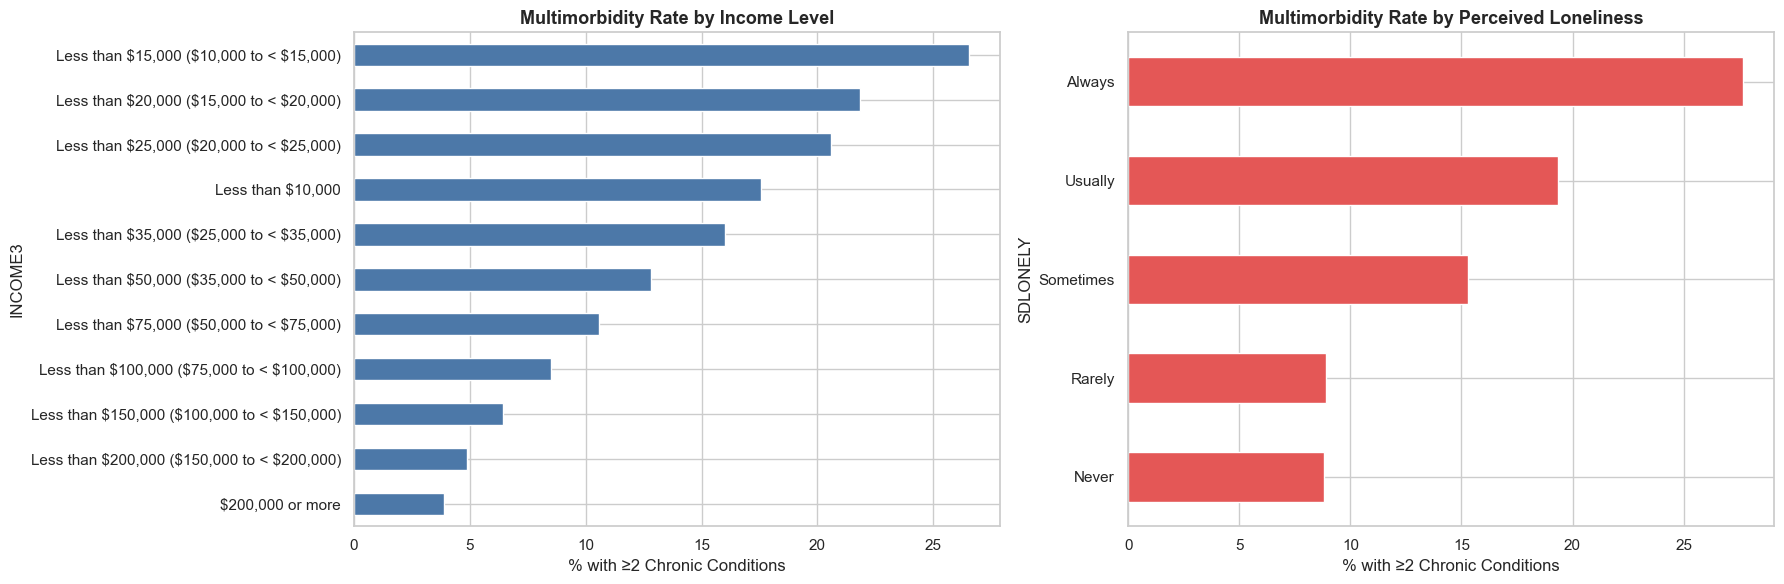

2026-10-31 13:29:12 [INFO] STEP 13: Analysis and visualizations complete.


In [15]:
# ── Step 13: Multimorbidity by Income & Loneliness ─────────────────────────────
logger.info("STEP 13: Analyzing multimorbidity by income level and loneliness...")

# Multimorbidity by Income
print("--- Multimorbidity Rate (%) by Income Level ---")
mm_income = df_flags.groupby('INCOME3')['Multimorbidity_Flag'].mean() * 100
print(mm_income.sort_values(ascending=False))

# Multimorbidity by Loneliness
print("\n--- Multimorbidity Rate (%) by Loneliness ---")
mm_lonely = df_flags.groupby('SDLONELY')['Multimorbidity_Flag'].mean() * 100
print(mm_lonely.sort_values(ascending=False))

# Visualize SDOH Associations
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

mm_income.sort_values().plot.barh(ax=axes[0], color='#4c78a8')
axes[0].set_title('Multimorbidity Rate by Income Level', fontsize=13, fontweight='bold')
axes[0].set_xlabel('% with ≥2 Chronic Conditions')

mm_lonely.sort_values().plot.barh(ax=axes[1], color='#e45756')
axes[1].set_title('Multimorbidity Rate by Perceived Loneliness', fontsize=13, fontweight='bold')
axes[1].set_xlabel('% with ≥2 Chronic Conditions')

plt.tight_layout()
plt.show()
logger.info("STEP 13: Analysis and visualizations complete.")


### Step 14: Machine Learning Baseline — Survey-Weighted Multimorbidity Classification <a id='step-14'></a>
Construct a production-grade scikit-learn pipeline for predicting `Multimorbidity_Flag`:
- **Strict Data Leakage Prevention:** Drops constituent conditions (`Diabetes_Flag`, `_MICHD`, `CVDSTRK3`, etc.) and tracking IDs.
- **Preprocessing Pipeline:** Imputes median for numeric features, standardizes variance, imputes mode for categoricals, and one-hot encodes.
- **Survey-Weighted Stratified Split:** Uses complex survey weights (`_LLCPWT`).


In [16]:
# ── Step 14: Machine Learning Pipeline for Multimorbidity (Leakage-Free) ────────
logger.info("STEP 14: Setting up Machine Learning pipeline for Multimorbidity prediction...")

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

# 1. Define Target and Prevent Data Leakage
target = 'Multimorbidity_Flag'

# Leakage variables: constituent conditions, target proxy variables, and direct derivative classifications
leakage_cols = [
    'Diabetes_Flag', 'Cardiovascular_Disease_Flag', 'Stroke_Flag', 
    'Kidney_Disease_Flag', 'Depression_Flag', 'Chronic_Disease_Count',
    'DIABETE4', 'CVDINFR4', 'CVDCRHD4', '_MICHD', 'CVDSTRK3', 'CHCKDNY2', 'ADDEPEV3',
    'PREDIAB2', '_PHYS14D', '_MENT14D'  # PREDIAB2 is a direct proxy of diabetes; 14-day indicators leak health day targets
]

# Isolate valid rows
df_ml = df_flags.dropna(subset=[target]).copy()
logger.info(f"STEP 14: Training cohort size: {df_ml.shape[0]:,} rows.")

# 2. Outlier Capping Before Training
if '_DRNKWK3' in df_ml.columns:
    df_ml['_DRNKWK3'] = np.where(pd.to_numeric(df_ml['_DRNKWK3'], errors='coerce') > 35.0, 35.0, pd.to_numeric(df_ml['_DRNKWK3'], errors='coerce'))
if '_BMI5' in df_ml.columns:
    df_ml['_BMI5'] = np.where(pd.to_numeric(df_ml['_BMI5'], errors='coerce') > 60.0, 60.0, pd.to_numeric(df_ml['_BMI5'], errors='coerce'))

# Drop leakage features, target itself, and tracking identifiers
cols_to_drop = [c for c in leakage_cols + [target, 'IDATE', 'is_complete', '_STSTR', '_PSU'] if c in df_ml.columns]
X_full = df_ml.drop(columns=cols_to_drop)
y = df_ml[target]
weights = pd.to_numeric(df_ml['_LLCPWT'], errors='coerce').fillna(1.0) if '_LLCPWT' in df_ml.columns else pd.Series(1.0, index=df_ml.index)

# Select key curated predictors for clinically grounded, high-performance modeling
curated_features = [
    '_AGE80', '_BMI5', 'PHYSHLTH', 'MENTHLTH', '_DRNKWK3', 'CHILDREN',
    'GENHLTH', 'EXERANY2', '_TOTINDA', 'SMOKE100', 'SMOKDAY2', '_RFSMOK3',
    'EDUCA', 'INCOME3', '_INCOMG1', 'EMPLOY1', 'MARITAL', 'SEXVAR',
    '_RACE', '_HISPANC', '_STATE', 'PRIMINS2', 'CHECKUP1', 'DIFFWALK',
    'DIFFDRES', 'DIFFALON', 'SDLONELY', 'LSATISFY'
]
use_features = [c for c in curated_features if c in X_full.columns]
X = X_full[use_features].copy()

# 3. Robust Separation of Numeric and Categorical Features
num_cols = [c for c in ['_AGE80', '_BMI5', 'PHYSHLTH', 'MENTHLTH', '_DRNKWK3', 'CHILDREN'] if c in X.columns]
for c in num_cols:
    X[c] = pd.to_numeric(X[c], errors='coerce')

cat_cols = [c for c in X.columns if c not in num_cols]
for c in cat_cols:
    X[c] = X[c].astype(object)

logger.info(f"Features: {len(num_cols)} numeric ({num_cols}), {len(cat_cols)} categorical.")

# 4. Build Preprocessing Pipeline
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

# 5. Stratified Train-Test Split with Survey Weights
X_train, X_test, y_train, y_test, w_train, w_test = train_test_split(
    X, y, weights, test_size=0.2, random_state=42, stratify=y
)

logger.info(f"STEP 14: Train set: {X_train.shape[0]:,} samples | Test set: {X_test.shape[0]:,} samples.")
print(f"ML Pipeline ready. Training set: {X_train.shape[0]:,} rows, Test set: {X_test.shape[0]:,} rows.")

# 6. Fit Logistic Regression with Survey Weights
clf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])
logger.info("STEP 14: Fitting Logistic Regression model...")
clf_pipeline.fit(X_train, y_train, classifier__sample_weight=w_train)

# 7. Evaluate Model on Holdout Set
y_pred = clf_pipeline.predict(X_test)
y_prob = clf_pipeline.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_prob, sample_weight=w_test)

print("\n=== Model Evaluation (Survey-Weighted Holdout Set) ===")
print(f"ROC-AUC Score: {auc:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, digits=4))
logger.info(f"STEP 14: ML Pipeline completed successfully. Holdout ROC-AUC = {auc:.4f}")


2026-10-28 02:38:16 [INFO] STEP 14: Setting up Machine Learning pipeline for Multimorbidity prediction...
2026-10-28 02:38:17 [INFO] STEP 14: Training cohort size: 456,780 rows.
2026-10-28 02:38:17 [INFO] Features: 6 numeric (['_AGE80', '_BMI5', 'PHYSHLTH', 'MENTHLTH', '_DRNKWK3', 'CHILDREN']), 22 categorical.
2026-10-28 02:38:18 [INFO] STEP 14: Train set: 365,424 samples | Test set: 91,356 samples.
2026-10-28 02:38:18 [INFO] STEP 14: Fitting Logistic Regression model...


ML Pipeline ready. Training set: 365,424 rows, Test set: 91,356 rows.


2026-10-28 02:38:24 [INFO] STEP 14: ML Pipeline completed successfully. Holdout ROC-AUC = 0.8582



=== Model Evaluation (Survey-Weighted Holdout Set) ===
ROC-AUC Score: 0.8582

Classification Report:
              precision    recall  f1-score   support

         0.0     0.9057    0.9824    0.9425     81264
         1.0     0.5544    0.1766    0.2678     10092

    accuracy                         0.8934     91356
   macro avg     0.7301    0.5795    0.6052     91356
weighted avg     0.8669    0.8934    0.8680     91356



---
## 6. Phase 5: Comprehensive Exploratory Data Analysis (EDA) Suite <a id='sec-6'></a>

Detailed visual profiling covering missingness, demographics, geography, physical health, and optional modules.

### Step 15.1: Missingness Profiling Across All 300+ Columns <a id='step-15-1'></a>
Calculate exact missingness percentages across every column in `BRFSS_clean.csv` and load an EDA sample.


In [17]:
# ── Step 15.1: Compute full dataset missingness profile ────────────────────────
logger.info("STEP 15.1: Calculating missingness across all columns...")

P_v2 = CLEAN_FILE
RD = dict(keep_default_na=False, na_values=[""])

cols_all = pd.read_csv(P_v2, nrows=0).columns
nulls_full, total_n = pd.Series(0.0, index=cols_all), 0

for ch in pd.read_csv(P_v2, chunksize=CHUNKSIZE, **RD):
    nulls_full += ch.isna().sum()
    total_n += len(ch)

null_pct_full = (nulls_full / total_n * 100).sort_values(ascending=False)
logger.info(f"STEP 15.1: Profiled {len(cols_all)} columns across {total_n:,} rows.")

# Load analytic subset for visualizations
use_eda = [
    "_STATE", "IDATE", "_AGE80", "_BMI5", "HTM4", "WTKG3", "_DRNKWK3",
    "PHYSHLTH", "MENTHLTH", "_LLCPWT",
    "SDLONELY", "LSATISFY", "FOODSTMP", "ACEDEPRS", "CIMEMLO1", "CAREGIV1", "MARJSMOK", "FIREARM5",
    "EMTSUPRT", "SDHBILLS", "SDHUTILS", "SDHTRNSP", "HOWSAFE1"
]
avail_eda = pd.read_csv(P_v2, nrows=0).columns
use_eda_present = [c for c in use_eda if c in avail_eda]
df_eda = pd.read_csv(P_v2, usecols=use_eda_present, **RD)
logger.info(f"STEP 15.1: Loaded EDA DataFrame. Shape: {df_eda.shape}")

2026-10-28 02:38:24 [INFO] STEP 15.1: Calculating missingness across all columns...
2026-10-28 02:38:32 [INFO] STEP 15.1: Profiled 125 columns across 457,670 rows.
2026-10-28 02:38:36 [INFO] STEP 15.1: Loaded EDA DataFrame. Shape: (457670, 23)


### Step 15.2: Visualizing Top 40 Most Incomplete Columns <a id='step-15-2'></a>
Rank and plot columns with the highest missingness rates (primarily optional state modules).


2026-10-28 02:38:36 [INFO] STEP 15.2: Plotting top 40 missing columns...


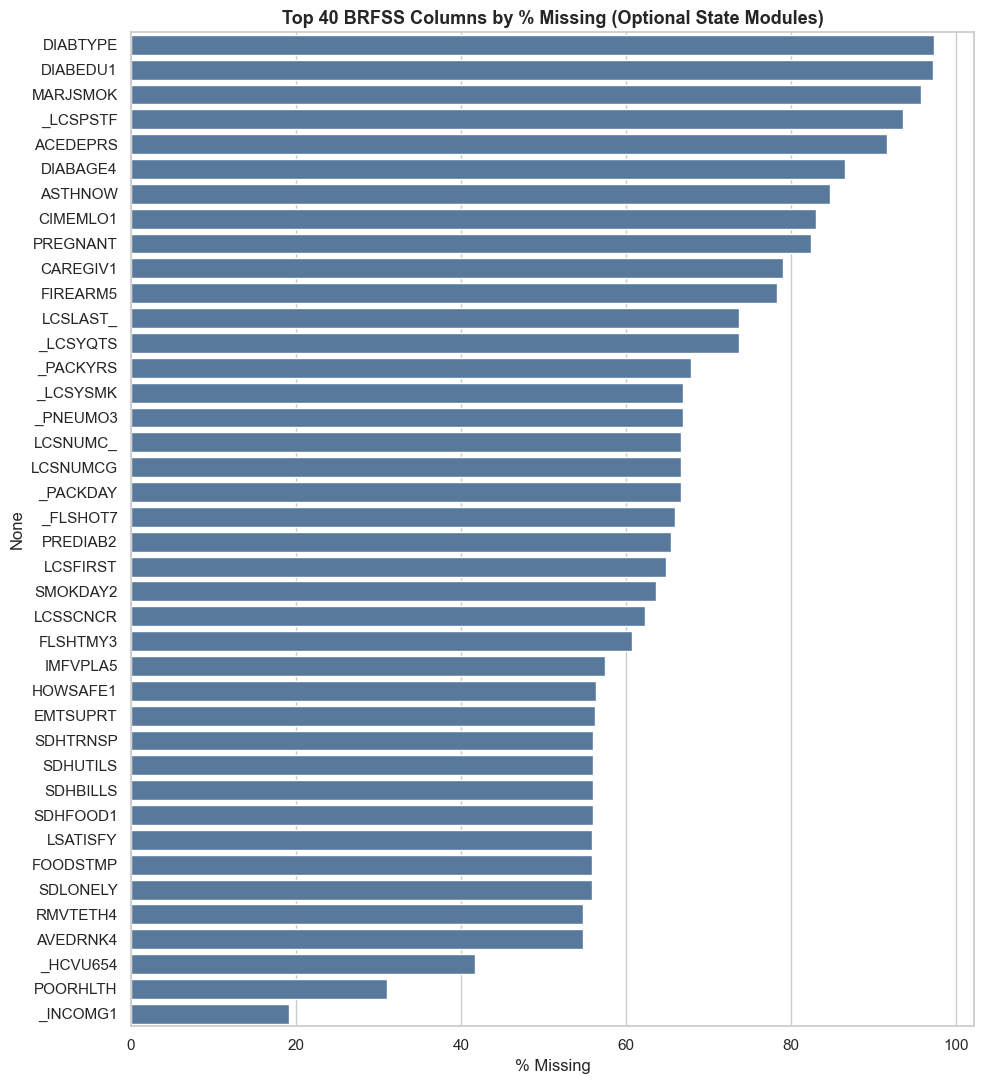

In [18]:
# ── Step 15.2: Plot Top 40 Incomplete Columns ──────────────────────────────────
logger.info("STEP 15.2: Plotting top 40 missing columns...")

top_40_missing = null_pct_full.head(40)
plt.figure(figsize=(10, 11))
sns.barplot(x=top_40_missing.values, y=top_40_missing.index, color="#4c78a8")
plt.title("Top 40 BRFSS Columns by % Missing (Optional State Modules)", fontsize=13, fontweight='bold')
plt.xlabel("% Missing")
plt.tight_layout()
plt.show()


### Step 15.3: Geographic Distribution — Survey Respondents by State <a id='step-15-3'></a>
Evaluate sample coverage across US states and territories.


2026-10-28 02:38:36 [INFO] STEP 15.3: Plotting respondents per state...


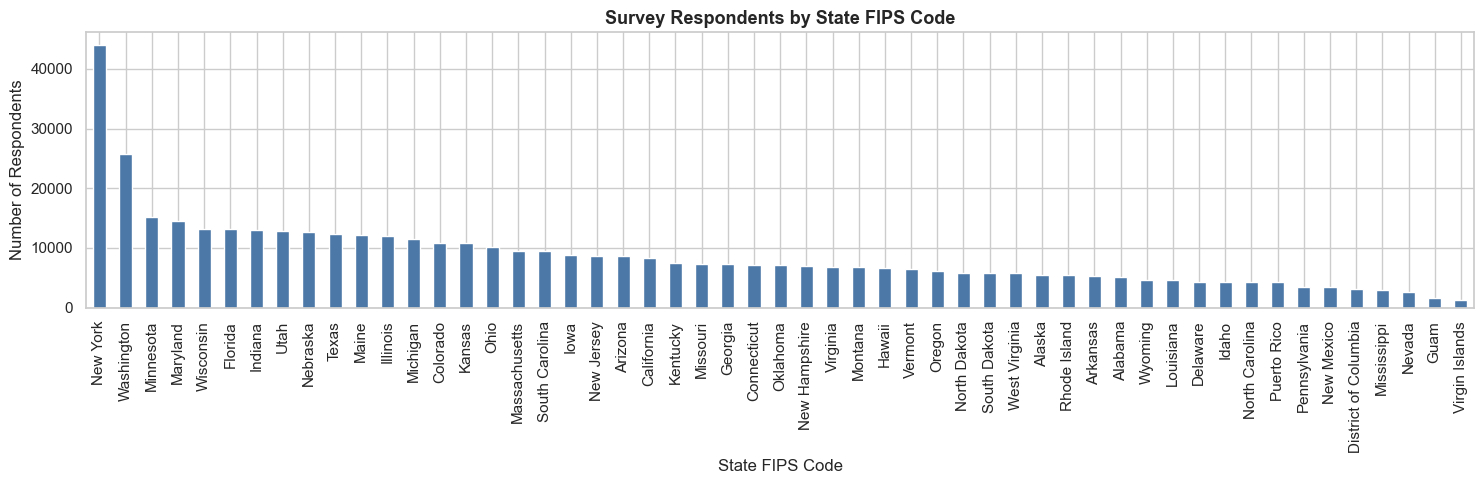

In [19]:
# ── Step 15.3: Geographic Distribution ────────────────────────────────────────
logger.info("STEP 15.3: Plotting respondents per state...")

state_counts = df_eda["_STATE"].value_counts()
plt.figure(figsize=(15, 5))
state_counts.plot.bar(color="#4c78a8")
plt.title("Survey Respondents by State FIPS Code", fontsize=13, fontweight='bold')
plt.ylabel("Number of Respondents")
plt.xlabel("State FIPS Code")
plt.tight_layout()
plt.show()


### Step 15.4: Temporal Distribution — Interviews Conducted per Month <a id='step-15-4'></a>
Parse survey interview dates (`IDATE`) to confirm interview volume across the calendar year.


2026-10-28 02:38:37 [INFO] STEP 15.4: Plotting monthly interview frequency...
2026-10-28 02:38:37 [INFO] Unparseable dates: 1 | Valid date range: 2024-01-01 00:00:00 to 2025-03-11 00:00:00


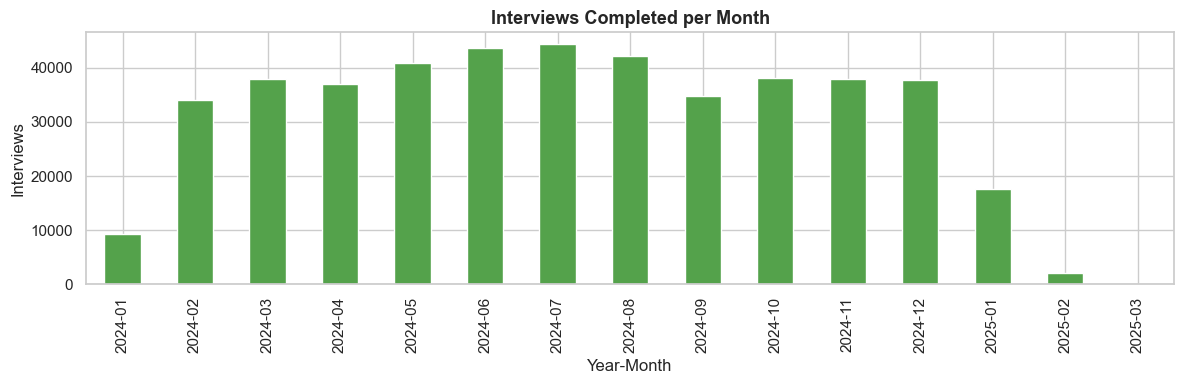

In [20]:
# ── Step 15.4: Temporal Distribution ──────────────────────────────────────────
logger.info("STEP 15.4: Plotting monthly interview frequency...")

if "IDATE" in df_eda.columns and df_eda["IDATE"].notna().any():
    dates = pd.to_datetime(df_eda["IDATE"], errors="coerce")
    logger.info(f"Unparseable dates: {dates.isna().sum()} | Valid date range: {dates.min()} to {dates.max()}")

    plt.figure(figsize=(12, 4))
    dates.dt.to_period("M").value_counts().sort_index().plot.bar(color="#54a24b")
    plt.title("Interviews Completed per Month", fontsize=13, fontweight='bold')
    plt.ylabel("Interviews")
    plt.xlabel("Year-Month")
    plt.tight_layout()
    plt.show()
else:
    logger.info("IDATE column not available; skipping monthly interview plot.")

### Step 15.5: Demographic Distribution — Age (Capped at 80) <a id='step-15-5'></a>
Plot the respondent age distribution from `_AGE80`.


2026-10-28 02:38:37 [INFO] STEP 15.5: Plotting age distribution...


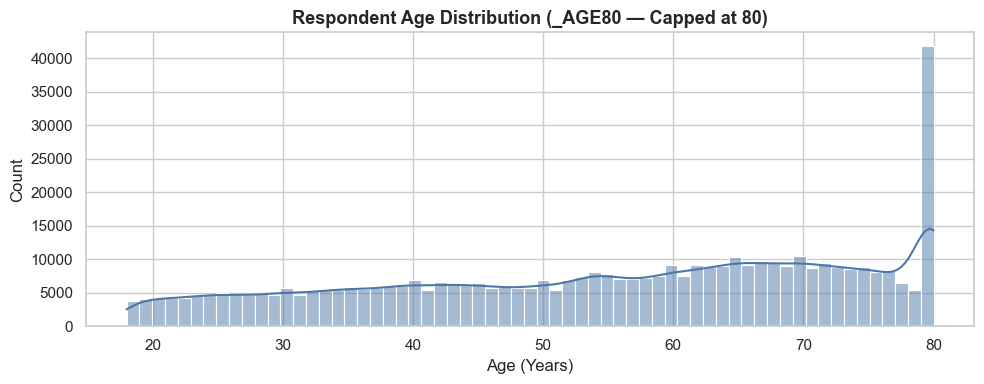

In [21]:
# ── Step 15.5: Age Distribution ───────────────────────────────────────────────
logger.info("STEP 15.5: Plotting age distribution...")

plt.figure(figsize=(10, 4))
sns.histplot(df_eda["_AGE80"].dropna(), bins=63, color="#4c78a8", kde=True)
plt.title("Respondent Age Distribution (_AGE80 — Capped at 80)", fontsize=13, fontweight='bold')
plt.xlabel("Age (Years)")
plt.tight_layout()
plt.show()


### Step 15.6: Physical Health Metrics — Height vs. Weight & BMI Distribution <a id='step-15-6'></a>
Examine bivariate scatter of height vs. weight alongside BMI distribution and boxplot outliers.


2026-10-28 02:38:38 [INFO] STEP 15.6: Plotting Height, Weight and BMI distributions...


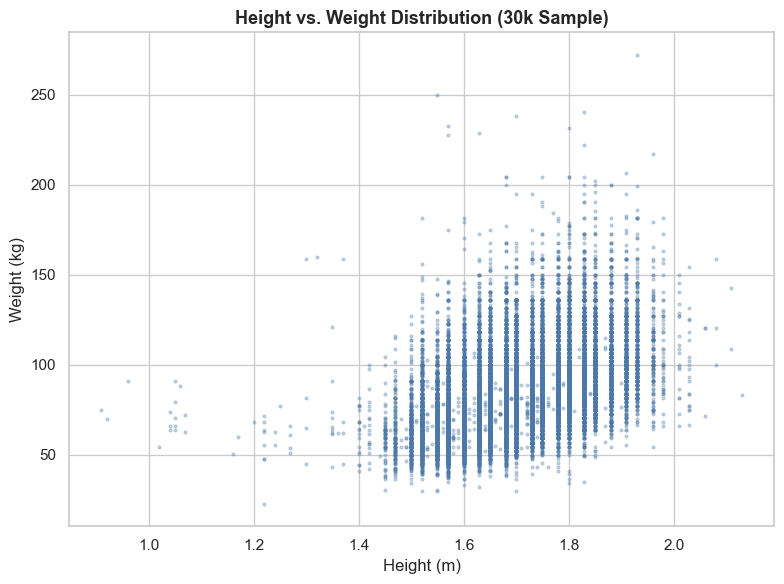

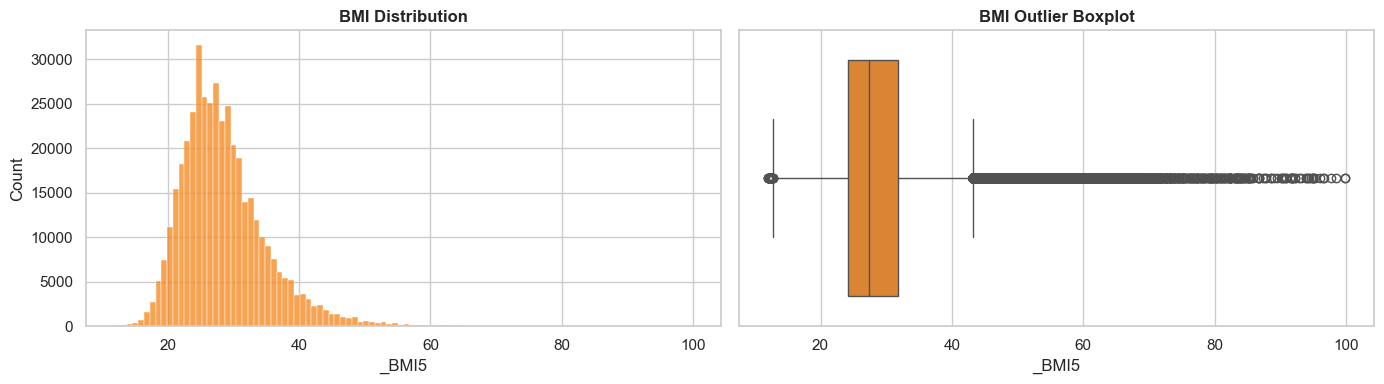

BMI Descriptive Statistics:
count    414633.0
mean         28.6
std           6.6
min          12.0
25%          24.1
50%          27.4
75%          31.8
max          99.8
Name: _BMI5, dtype: float64


In [22]:
# ── Step 15.6: Physical Health Metrics ─────────────────────────────────────────
logger.info("STEP 15.6: Plotting Height, Weight and BMI distributions...")

# Sample for scatter plot
hw_sample = df_eda[["HTM4", "WTKG3"]].dropna().sample(min(30_000, len(df_eda)), random_state=1)

plt.figure(figsize=(8, 6))
plt.scatter(hw_sample["HTM4"], hw_sample["WTKG3"], s=4, alpha=0.3, color='#4c78a8')
plt.xlabel("Height (m)")
plt.ylabel("Weight (kg)")
plt.title("Height vs. Weight Distribution (30k Sample)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# BMI Histplot & Boxplot
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df_eda["_BMI5"].dropna(), bins=100, ax=ax[0], color="#f58518")
ax[0].set_title("BMI Distribution", fontsize=12, fontweight='bold')

sns.boxplot(x=df_eda["_BMI5"].dropna(), ax=ax[1], color="#f58518")
ax[1].set_title("BMI Outlier Boxplot", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("BMI Descriptive Statistics:")
print(df_eda["_BMI5"].describe().round(1))


### Step 15.7: Optional Module Completion Rate Heatmap by State <a id='step-15-7'></a>
Visualize state-level adoption for optional BRFSS modules: Loneliness (`SDLONELY`), Life Satisfaction (`LSATISFY`), Food Stamps (`FOODSTMP`), Adverse Childhood Experiences (`ACEDEPRS`), Cognitive Decline (`CIMEMLO1`), Caregiving (`CAREGIV1`), Marijuana (`MARJSMOK`), and Firearms (`FIREARM5`).


2026-10-28 02:38:40 [INFO] STEP 15.7: Plotting optional module answer rates by state...


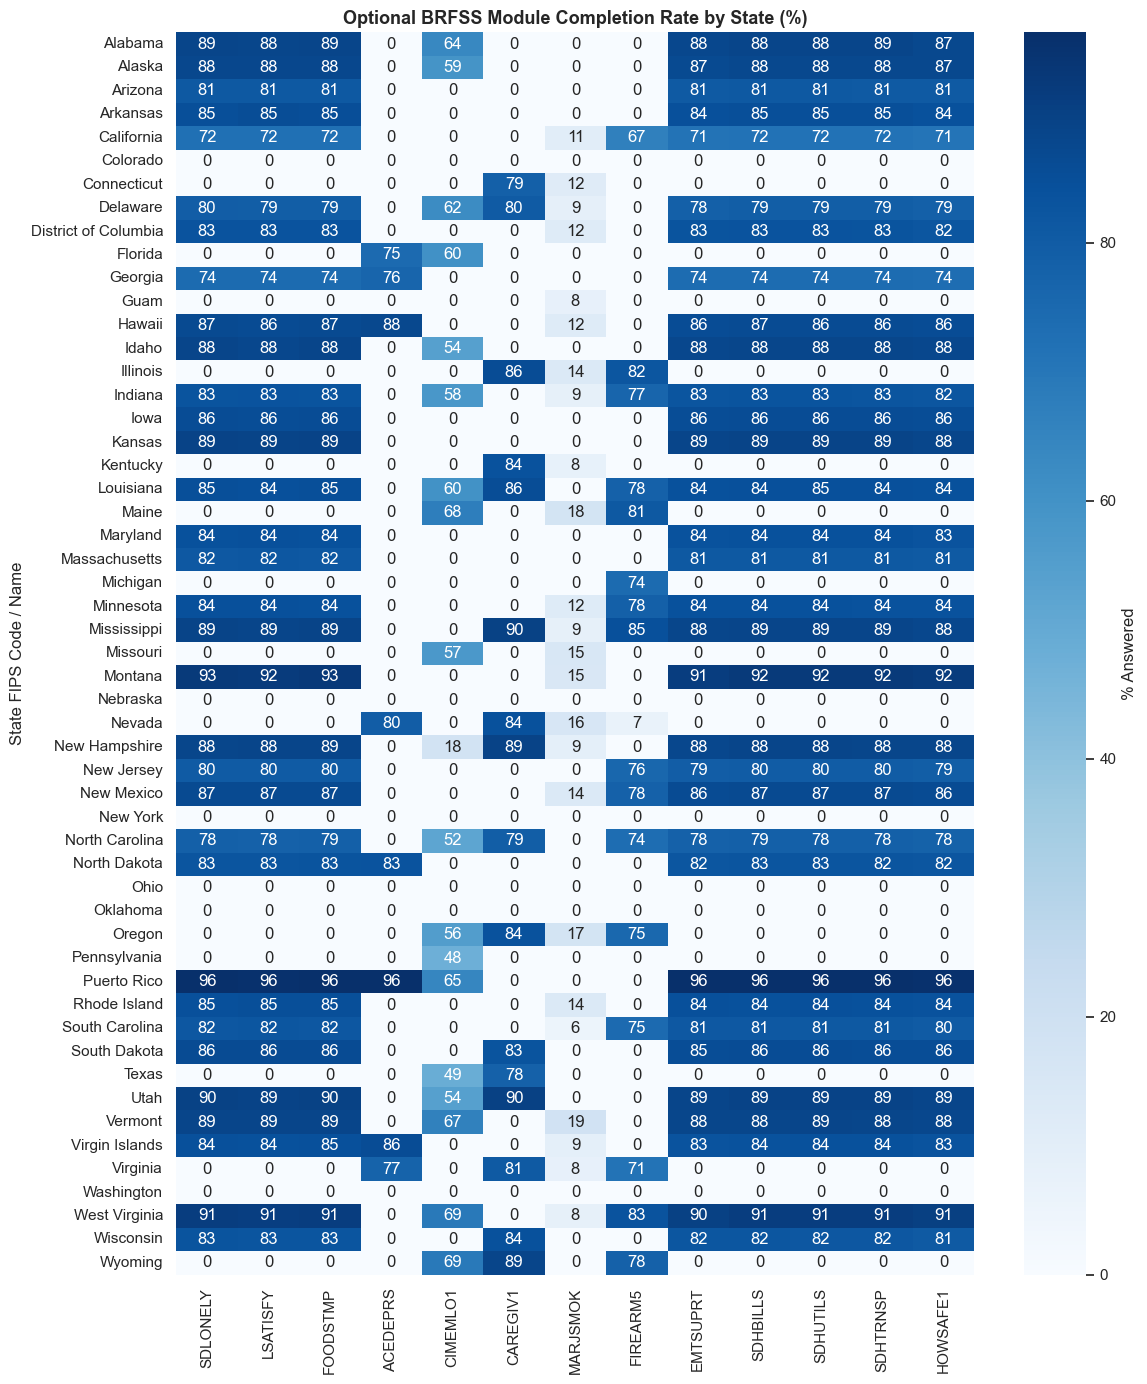

In [23]:
# ── Step 15.7: State Module Completion Heatmap ─────────────────────────────────
logger.info("STEP 15.7: Plotting optional module answer rates by state...")

modules = ["SDLONELY", "LSATISFY", "FOODSTMP", "ACEDEPRS", "CIMEMLO1", "CAREGIV1", "MARJSMOK", "FIREARM5", "EMTSUPRT", "SDHBILLS", "SDHUTILS", "SDHTRNSP", "HOWSAFE1"]
present_mods = [m for m in modules if m in df_eda.columns]

if present_mods and "_STATE" in df_eda.columns:
    rate = df_eda.groupby("_STATE")[present_mods].agg(lambda x: x.notna().mean() * 100)
    plt.figure(figsize=(12, 14))
    sns.heatmap(rate, cmap="Blues", annot=True, fmt=".0f", cbar_kws={"label": "% Answered"})
    plt.title("Optional BRFSS Module Completion Rate by State (%)", fontsize=13, fontweight='bold')
    plt.ylabel("State FIPS Code / Name")
    plt.tight_layout()
    plt.show()

### Step 15.8: Behavioral Distributions — Alcohol Intake & Health Quality Days <a id='step-15-8'></a>
Plot distributions of weekly alcohol consumption on log scale alongside 30-day physical and mental unhealthy day counts.


2026-10-28 02:38:41 [INFO] STEP 15.8: Plotting alcohol intake and unhealthy days...


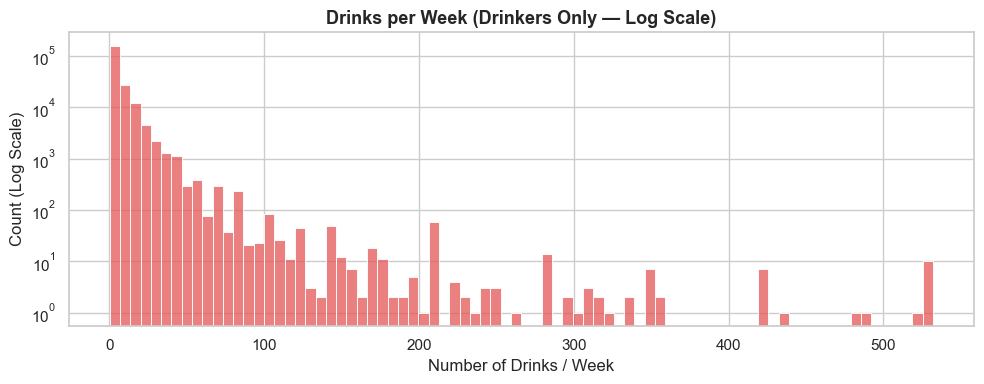

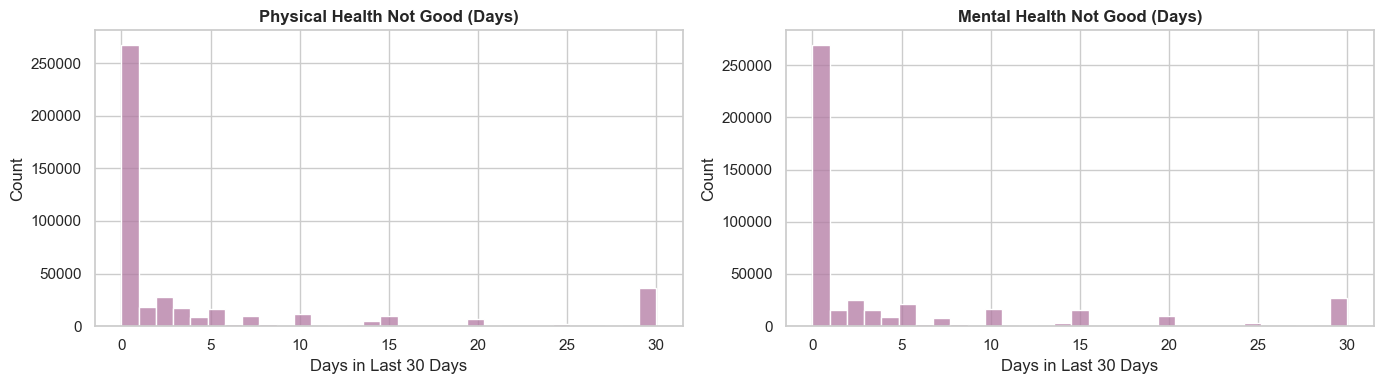

2026-10-28 02:38:42 [INFO] STEP 15.8: Completed behavioral health visualizations.


In [24]:
# ── Step 15.8: Behavioral Health Distributions ─────────────────────────────────
logger.info("STEP 15.8: Plotting alcohol intake and unhealthy days...")

# 1. Weekly alcohol consumption (log scale)
drinks = df_eda["_DRNKWK3"].dropna()
plt.figure(figsize=(10, 4))
sns.histplot(drinks[drinks > 0], bins=80, color="#e45756")
plt.yscale("log")
plt.title("Drinks per Week (Drinkers Only — Log Scale)", fontsize=13, fontweight='bold')
plt.xlabel("Number of Drinks / Week")
plt.ylabel("Count (Log Scale)")
plt.tight_layout()
plt.show()

# 2. 30-day Physical and Mental Health Days
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col, title in zip(axes, ["PHYSHLTH", "MENTHLTH"], ["Physical Health Not Good (Days)", "Mental Health Not Good (Days)"]):
    sns.histplot(df_eda[col].dropna(), bins=31, ax=ax, color="#b279a2")
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel("Days in Last 30 Days")
plt.tight_layout()
plt.show()

logger.info("STEP 15.8: Completed behavioral health visualizations.")


---
## 7. Phase 6: Survey-Weighted Epidemiological Analysis <a id='sec-7'></a>

Compute population-representative health statistics using complex survey sampling weights (`_LLCPWT`).

### Step 16: Survey-Weighted Prevalence Cross-Tabulations (`_LLCPWT`) <a id='step-16'></a>
Functions to calculate weighted percentages:
$$\text{Weighted } \% = \frac{\sum w_i \cdot \mathbb{I}(y_i = \text{Yes})}{\sum w_i} \times 100$$
Evaluates weighted diabetes prevalence by income category (`_INCOMG1`) and depression prevalence by age band (`_AGEG5YR`).


In [25]:
# ── Step 16: Survey-Weighted Prevalence Cross-Tabulations ──────────────────────
logger.info("STEP 16: Calculating survey-weighted prevalence estimates...")

def load_weighted_cols(cols):
    """Load requested columns along with core survey design variables."""
    avail = pd.read_csv(CLEAN_FILE, nrows=0).columns
    target_cols = ["_PSU", "_STATE", "_LLCPWT"] + cols
    valid_cols = list(dict.fromkeys([c for c in target_cols if c in avail]))
    return pd.read_csv(CLEAN_FILE, usecols=valid_cols, **RD)

def wpct(df, group, flag, yes_val="Yes"):
    """
    Compute survey-weighted prevalence (%) within each demographic stratum.
    Excludes missing values from denominator.
    """
    d = df[[group, flag, "_LLCPWT"]].dropna().copy()
    d["w_yes"] = d["_LLCPWT"] * (d[flag] == yes_val)
    g = d.groupby(group, observed=True)
    out = pd.DataFrame({
        "weighted_%": (g["w_yes"].sum() / g["_LLCPWT"].sum() * 100).round(1),
        "n_unweighted": g.size()
    })
    return out.sort_values("weighted_%", ascending=False)

# Analyze Diabetes by Income & Depression by Age
d_weighted = load_weighted_cols(["DIABETE4", "ADDEPEV3", "_INCOMG1", "_AGEG5YR"])

if "DIABETE4" in d_weighted.columns and "_INCOMG1" in d_weighted.columns:
    print("=== Weighted Diabetes Prevalence by Income Group ===")
    display(wpct(d_weighted, "_INCOMG1", "DIABETE4"))

if "ADDEPEV3" in d_weighted.columns and "_AGEG5YR" in d_weighted.columns:
    print("\n=== Weighted Depression Prevalence by Age Group ===")
    display(wpct(d_weighted, "_AGEG5YR", "ADDEPEV3"))

logger.info("STEP 16: Weighted estimations complete.")

2026-10-28 02:38:42 [INFO] STEP 16: Calculating survey-weighted prevalence estimates...


=== Weighted Diabetes Prevalence by Income Group ===


,weighted_%,n_unweighted
_INCOMG1,,
"$15,000 to < $25,000",20.5,33391
"Less than $15,000",18.4,20722
"$25,000 to < $35,000",16.6,41619
"$35,000 to < $50,000",14.7,49603
"$50,000 to < $100,000",11.4,112295
"$100,000 to < $200,000",8.8,82400
"$200,000 or more",6.5,29676



=== Weighted Depression Prevalence by Age Group ===


,weighted_%,n_unweighted
_AGEG5YR,,
Age 30 to 34,25.6,26077
Age 25 to 29,25.4,23525
Age 18 to 24,25.0,29378
Age 35 to 39,23.5,28641
Age 40 to 44,22.8,30735
Age 45 to 49,22.0,28841
Age 50 to 54,21.4,31570
Age 55 to 59,21.0,34769
Age 60 to 64,20.1,43201


2026-10-28 02:38:46 [INFO] STEP 16: Weighted estimations complete.


### Step 17: Multivariable Heatmap — Diabetes Prevalence by Income & Age Group <a id='step-17'></a>
Build an epidemiological heatmap of weighted diabetes prevalence cross-classified simultaneously by income tier and age bracket.


2026-10-28 02:38:46 [INFO] STEP 17: Generating multivariable weighted diabetes heatmap...


Weighted Diabetes Prevalence Pivot Matrix (%):


_AGE_G,Age 18 to 24,Age 25 to 34,Age 35 to 44,Age 45 to 54,Age 55 to 64,Age 65 or older
_INCOMG1,,,,,,
"Less than USD 15,000",2.4,3.4,9.4,24.4,30.7,34.0
"USD 15,000 to < USD 25,000",2.9,4.2,10.1,27.2,31.7,32.5
"USD 25,000 to < USD 35,000",2.9,3.1,9.2,19.6,27.7,28.3
"USD 35,000 to < USD 50,000",2.4,3.0,7.6,17.4,24.4,25.7
"USD 50,000 to < USD 100,000",1.1,2.3,5.3,13.6,18.7,21.0
"USD 100,000 to < USD 200,000",0.9,1.9,4.6,10.5,14.9,17.1
"USD 200,000 or more",2.1,1.8,2.7,6.2,12.0,15.6


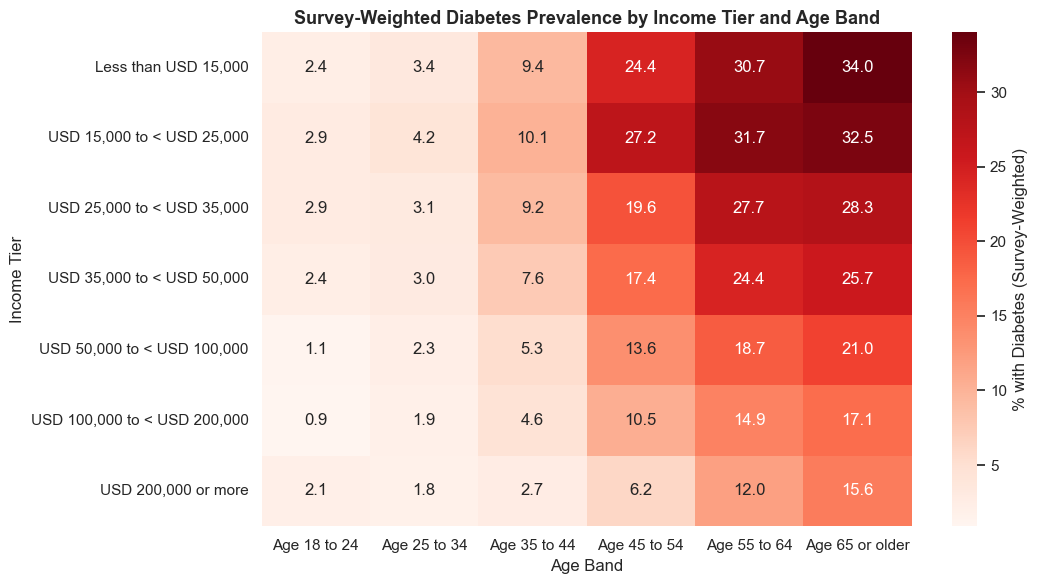

2026-10-28 02:38:49 [INFO] STEP 17: Final heatmap generated successfully. Pipeline finished!


In [26]:
# ── Step 17: Diabetes x Income x Age Heatmap ──────────────────────────────────
logger.info("STEP 17: Generating multivariable weighted diabetes heatmap...")

d_heat = load_weighted_cols(["DIABETE4", "_INCOMG1", "_AGE_G"])

if all(c in d_heat.columns for c in ["DIABETE4", "_INCOMG1", "_AGE_G"]):
    d_heat["_INCOMG1"] = d_heat["_INCOMG1"].astype(str).str.replace("$", "USD ", regex=False)

    income_order = [
        "Less than USD 15,000", "USD 15,000 to < USD 25,000", "USD 25,000 to < USD 35,000",
        "USD 35,000 to < USD 50,000", "USD 50,000 to < USD 100,000",
        "USD 100,000 to < USD 200,000", "USD 200,000 or more"
    ]
    age_order = ["Age 18 to 24", "Age 25 to 34", "Age 35 to 44",
                 "Age 45 to 54", "Age 55 to 64", "Age 65 or older"]

    t = d_heat.dropna(subset=["_INCOMG1", "_AGE_G", "DIABETE4"]).copy()
    t["w_yes"] = t["_LLCPWT"] * (t["DIABETE4"] == "Yes")
    g = t.groupby(["_INCOMG1", "_AGE_G"], observed=True)
    pv = (g["w_yes"].sum() / g["_LLCPWT"].sum() * 100).unstack().round(1)

    pv = pv.reindex(
        index=[o for o in income_order if o in pv.index],
        columns=[a for a in age_order if a in pv.columns]
    )

    print("Weighted Diabetes Prevalence Pivot Matrix (%):")
    display(pv)

    plt.figure(figsize=(11, 6))
    sns.heatmap(pv, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "% with Diabetes (Survey-Weighted)"})
    plt.title("Survey-Weighted Diabetes Prevalence by Income Tier and Age Band", fontsize=13, fontweight='bold')
    plt.ylabel("Income Tier")
    plt.xlabel("Age Band")
    plt.tight_layout()
    plt.show()

logger.info("STEP 17: Final heatmap generated successfully. Pipeline finished!")

---

## Summary of Generated Deliverables

| Artifact | File Path | Description |
|:---|:---|:---|
| **Clean Dataset** | `BRFSS_clean.csv` | Final chunk-cleaned dataset: short column codes, skip routing stripped, zeros restored, numerics rescaled, `is_complete` flag added, `SEQNO` kept as record ID |
| **Star-Schema Plan** | `star_schema_planning.csv` | Full column catalog exported for relational database modeling |
| **Null Audit Log** | `compare_nulls.csv` | Differential before-and-after missingness statistics across all columns |

> **Portability Note:** All input and output paths are resolved dynamically relative to the current notebook folder. To share this project, simply distribute the folder containing `BRFSS_Pipeline_Organised.ipynb` and `BRFSS_2024_Expanded_Analysis.csv`.
